# RQ2 on Test Case C (AP1D electrophysiology): how much nonlinearity does the LDNet reconstructor need?

This notebook runs **Test Case C only** of `RQ2/RQ2_protocol.md`. The problem is the 1D Monodomain + Aliev-Panfilov model of the original `src/TestCase_3.py` (excitable tissue on $x \in (0,100)$, $t \in (0,500]$ ms, homogeneous Neumann + zero IC):

$$
\frac{\partial z}{\partial t} - D\frac{\partial^2 z}{\partial x^2} = Kz(1-z)(z-\alpha) - zw + I_{\mathrm{stim}}(x,t), \qquad \mathbf{u}(t)=(I_{\mathrm{app},1},I_{\mathrm{app},2}),
$$

with square stimulation pulses at $x=L/4$ and $3L/4$. The LDNet predicts the action-potential travelling fronts $z(x,t)$: stiff, sharp depolarization fronts and slow repolarization, i.e. slow Kolmogorov $n$-width where a linear decoder should struggle (protocol H2).

## Experiment

An LDNet is $\mathcal{NN}_{\mathrm{dyn}}$ (latent dynamics, Forward Euler, $\mathbf{s}(0)=0$) followed by a **reconstructor**. Only the reconstructor changes between the variants of the protocol (Sec. 4). Data, splits, normalisation, $\mathcal{NN}_{\mathrm{dyn}}$ (8-$d_s$ base with equilibrium subtraction, see below), loss (MSE + $4.7\cdot 10^{-3}$ Tikhonov) and optimizer (200 Adam + 500 BFGS epochs, same reduced-budget policy as case B) are the same everywhere. The reconstructor takes $(\mathbf{s},x)$ only, as in the original script (unlike case B, no $u(t)$ input and no output transform). The linear variants add the mean field $\bar y(x)$ (mean of the full-grid training fields) and use the Legendre basis $\varphi_k$ on $[-1,1]$, orthonormalised on the 101-point grid with the trapezoidal discrete $L^2$ product $\langle f,g\rangle_w = \sum_i w_i f(x_i)g(x_i)$ (the grid includes both endpoints, Neumann).

| Variant | Reconstructor | Trainable |
|---|---|---|
| L0 | $\mathcal{NN}_{\mathrm{rec}}(\mathbf{s},x)$, the original $17^5 \to 1$ | MLP |
| L1 | $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$ | none |
| L2 | $\bar y+\sum_{k=1}^{K}(W\mathbf{s}+\mathbf{b})_k\varphi_k$ | $W,\mathbf{b}$ |
| L3 | $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{s})_k\varphi_k$ | $g_\theta$ |

Two training regimes (Sec. 5):
- **R1, frozen latents**: the L0 run with the same $(d_s,\text{seed})$ provides $\mathbf{s}(t)$; only the new reconstructor is fitted on these latents.
- **R2, end-to-end**: $\mathcal{NN}_{\mathrm{dyn}}$ and the reconstructor are trained together from scratch.

Sweep: $d_s \in \{1,2,3,5,12\}$ (protocol $\{1,2,3,5\}$ plus the original $d_s=12$ as the L0 anchor), $K \in \{d_s,5,17,33\}$, R1 and R2, 3 seeds. L1 has $K=d_s$ and L0 has no $K$ (stored as `K = 0`). For L0, R1 and R2 coincide: L0 is trained once, end-to-end, and its latents are the input of R1.

Not included in v1: the "best size" sweep of $g_\theta$ (its width matches the parameter count of the L0 reconstructor), the per-mode analysis of the trained L0 decoder (protocol Sec. 9) and the Wilcoxon/Holm statistics (protocol Sec. 10).

## How to use

1. Run the **Setup**, **Experiment configuration** and **Helpers** cells (they are cheap: after a kernel restart run only these, then any analysis cell).
2. Run the variant sections in order. Each one trains its sweep, then draws its boxplots and trend plots. R1 of L1-L3 re-uses the latents saved by the L0 section.
3. The **final comparison** only reads results.

Budget: this folder holds a **single reduced-budget sweep** (200 Adam + 500 BFGS, same policy as case B; the original script uses 5000 BFGS). This pipeline has no early stopping (final-epoch weights are used), so these numbers are conditional on the budget and the L0 gate against the full-budget paper reference stays provisional. A full-budget rerun would re-train everything from scratch in another `OUT` folder: the guard in *Experiment configuration* refuses other training settings in the same folder.

Time: TODO after timing one L0 run at 200+500 alone (do not time anything while another heavy job runs: TF uses every core; multiply by 273 for the sweep total). The gate in the L0 section is provisional until then (paper reference at full budget, $d_s=12$: test NRMSE $7.37\cdot 10^{-3}$).

Everything is stored in `results/`, so more analyses never require re-training:
- `runs.csv`, `predictions.csv`, `modes.csv`: one row per run / test prediction / Legendre mode (columns in the *Metrics* cell);
- `weights/`: trained parameters of every run, a run can be rebuilt without re-training (`predict_test`);
- `latents/`: the L0 latent states $\mathbf{s}(t)$ used by R1;
- `meta.json`: library versions, git hash of the first session and the training settings.

A sweep cell skips the runs already in `runs.csv`: it can be interrupted and resumed, and re-running the whole notebook only re-draws the plots. To investigate further, add cells that read the tables with `load('runs')`, `load('predictions')`, `load('modes')`.

**Reproducibility.** The train/valid point subsampling is fixed across seeds (`np.random.seed(0)` once before the three `process_dataset` calls, in the original order), so the datasets reproduce the original script. Every run calls `set_seed(seed)` before any network is created and TensorFlow runs in deterministic mode on the CPU in float64. `rec` takes `(states, split)` instead of `(states)` (Case A contract): train/valid use the 20 sampled points per $(sample,t)$ and the test uses the full grid, so both the points (L0) and the gathered mean field (L1-L3) depend on the split. The Legendre basis itself is analytic and evaluated once on the full grid (first $K$ columns are the $K$ modes, so extending the sweep later does not change it).

## Setup

In [1]:
# import modules
import contextlib
import io
import json
import pathlib
import subprocess
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.stats
import tensorflow as tf

# We configure TensorFlow to work in double precision
tf.keras.backend.set_floatx('float64')

# Double precision must run on the CPU here: the Apple Metal GPU plugin only registers
# single-precision kernels (e.g. ResourceApplyAdam with T=DT_DOUBLE is missing).
# We first try to hide the GPU; if the kernel already initialized it (e.g. this cell is
# re-run in an old session), we fall back to creating all model variables on /CPU:0.
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass  # devices already initialized: fall back to the CPU device scope below
if tf.config.get_visible_devices('GPU'):
    print('GPU already initialized -> model variables will be created on /CPU:0.')
    cpu_device = lambda: tf.device('/CPU:0')
else:
    print('Running on CPU (float64).')
    cpu_device = contextlib.nullcontext

# Reproducibility: deterministic TensorFlow kernels. Random initialisers then require tf.random.set_seed,
# which setup_run() calls right before it creates the networks of a run.
tf.config.experimental.enable_op_determinism()

# Every run builds new tf.functions: this silences the "tf.function retracing" warnings that this triggers.
tf.get_logger().setLevel('ERROR')

import utils
import optimization

# utils.py is the copy in this folder: identical to src/ except process_dataset also stores
# dataset['idxs'] (None without subsampling), needed to gather the mean field at the sampled points.
print('utils        ->', utils.__file__)
print('optimization ->', optimization.__file__)

/Users/giuliodonninelli/Dev/LDNets/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Running on CPU (float64).
utils        -> /Users/giuliodonninelli/Dev/LDNets/RQ2/AP1D/utils.py
optimization -> /Users/giuliodonninelli/Dev/LDNets/RQ2/AP1D/optimization.py


### Problem setting

We define the name of the variables of the problem at hand.

In [2]:
problem = {
    "space": {
        "dimension" : 1
    },
    "input_parameters": [ ],
    "input_signals": [
        { "name": "Iapp1" },
        { "name": "Iapp2" }
    ],
    "output_fields": [
        { "name": "u" }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [3]:
normalization = {
    'space': { 'min' : [0.0], 'max' : [100.0]},
    'time': { 'time_constant' : 205},
    'input_signals': {
        'Iapp1': { 'min': -2.5, 'max': 2.5},
        'Iapp2': { 'min': -2.5, 'max': 2.5},
    },
    'output_fields': {
        'u': { 'min': 0.0, "max": 1.2 }
    }
}

We define the time step size. The number of latent states $d_s$ is a factor of the sweep (next section).

In [4]:
dt = 1

### Datasets

We load training (100 samples), validation (100 samples) and testing (200 samples) data on the 101-point grid ($x \in [0,100]$, every 8th node of the 801-node mesh; $d = 1$, $d_{\mathbf{u}} = 2$, $d_{\mathbf{y}} = 1$; 501 time steps).
We resample the time transients with timestep `dt` (a no-op: the data already step by 1 ms) and we rescale each variable between -1 and 1. Train/valid use 20 random space points per (sample, time); the test set uses the full grid. Preserve the pulse timing exactly: no time decimation.

Each dataset is stored as a Python dictionary, with the following fields (shape is indicated in square brackets):
- `times` $[n_{\mathrm{times}}]$: time instants (501);
- `points` $[n_{\mathrm{points}}, d]$: space points (full grid, $[101, 1]$);
- `points_full` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d]$: space points repeated (or subsampled) for each sample and time instant;
- `inp_signals` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, d_{\mathbf{u}}]$: stimulation pulses for each sample and time instant;
- `out_fields` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, n_{\mathrm{points}}, d_{\mathbf{y}}]$: potentials for each sample, time instant and space point;
- `idxs` $[n_{\mathrm{samples}}, n_{\mathrm{times}}, 20]$ for train/valid (indices into the full grid), `None` for test.

`dataset_full` holds the full-grid training fields a second time (no subsampling: it consumes no RNG, so the sampling above is untouched) for the mean field only (41 MB).

In [5]:
data_set_path = '../../data/AP1D'

dataset_train = utils.AP_create_dataset(data_set_path, np.arange(  0, 100))
dataset_valid = utils.AP_create_dataset(data_set_path, np.arange(100, 200))
dataset_tests = utils.AP_create_dataset(data_set_path, np.arange(200, 400))
points_phys = dataset_tests['points'].copy()   # physical grid before normalisation (process_dataset works in place)

# For reproducibility (fixed subsampling across seeds, as in the original script)
np.random.seed(0)
tf.random.set_seed(0)

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt, num_points_subsample = 20)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt, num_points_subsample = 20)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

dataset_full = utils.AP_create_dataset(data_set_path, np.arange(0, 100))
utils.process_dataset(dataset_full, problem, normalization, dt = dt)

loaded sample 0
loaded sample 1
loaded sample 2
loaded sample 3
loaded sample 4
loaded sample 5
loaded sample 6
loaded sample 7
loaded sample 8
loaded sample 9
loaded sample 10
loaded sample 11
loaded sample 12
loaded sample 13
loaded sample 14
loaded sample 15
loaded sample 16
loaded sample 17
loaded sample 18
loaded sample 19
loaded sample 20
loaded sample 21
loaded sample 22
loaded sample 23
loaded sample 24
loaded sample 25
loaded sample 26
loaded sample 27
loaded sample 28
loaded sample 29
loaded sample 30
loaded sample 31
loaded sample 32
loaded sample 33
loaded sample 34
loaded sample 35
loaded sample 36
loaded sample 37
loaded sample 38
loaded sample 39
loaded sample 40
loaded sample 41
loaded sample 42
loaded sample 43
loaded sample 44
loaded sample 45
loaded sample 46
loaded sample 47
loaded sample 48
loaded sample 49
loaded sample 50
loaded sample 51
loaded sample 52
loaded sample 53
loaded sample 54
loaded sample 55
loaded sample 56
loaded sample 57
loaded sample 58
loaded 

## Experiment configuration

Sweep levels: protocol $\{1,2,3,5\}$ plus the original $d_s=12$ (19 $(d_s,K)$ configurations, 273 runs in total: 114 each for L2/L3, 30 for L1, 15 for L0). Training settings are identical for every variant and regime (Adam as in the original script; BFGS reduced to 500, see *Budget* above). Results already in `results/` are kept and the missing runs are added. The training settings cannot change inside one results folder (a guard checks it against `meta.json`): a full-budget rerun needs another `OUT`.

In [6]:
# ---- Sweep (protocol D_S = [1, 2, 3, 5] plus the original d_s = 12) ----
SEEDS = [0, 1, 2]                    # seed 0 is the seed of the original script
D_S = [1, 2, 3, 5, 12]               # number of latent states d_s
K_LEVELS = [5, 17, 33]               # number of modes K (every d_s also adds K = d_s)

def K_for(d_s):
    return sorted({d_s, *K_LEVELS})

# ---- Training: identical for every variant and regime ----
EPOCHS_ADAM, EPOCHS_BFGS, LR_ADAM, ALPHA_REG = 200, 500, 1e-2, 4.7e-3

# ---- Results folder ----
OUT = pathlib.Path('results')
(OUT / 'weights').mkdir(parents = True, exist_ok = True)
(OUT / 'latents').mkdir(exist_ok = True)

# The results of all the sessions must come from the same training settings (and the first session is recorded)
training = dict(epochs_adam = EPOCHS_ADAM, epochs_bfgs = EPOCHS_BFGS, lr_adam = LR_ADAM, alpha_reg = ALPHA_REG)
if (OUT / 'meta.json').exists():
    assert json.loads((OUT / 'meta.json').read_text())['training'] == training, f'{OUT}/ holds results with other training settings: use another OUT'
else:
    git = subprocess.run('git rev-parse --short HEAD', shell = True, capture_output = True, text = True).stdout.strip()
    (OUT / 'meta.json').write_text(json.dumps(dict(tensorflow = tf.__version__, numpy = np.__version__, scipy = scipy.__version__,
                                                   pandas = pd.__version__, git = git, training = training), indent = 2))

## Helpers

### Fixed ingredients

Everything that depends on data is computed from the **training set only**: the mean field $\bar y(x)$ and the Legendre basis, orthonormalised on the 101-point grid with the trapezoidal discrete $L^2$ product $\langle f,g\rangle_w = \sum_i w_i f(x_i)g(x_i)$ (uniform grid with both endpoints: half weight at the ends). The basis comes from a Legendre Vandermonde + weighted QR, so its first $K$ columns are the $K$ modes: extending the sweep later does not change it.

In [7]:
SPLITS = {'train': dataset_train, 'valid': dataset_valid, 'test': dataset_tests}
denorm = lambda a: np.asarray(utils.denormalize_output(a, problem, normalization))
REF = {s: denorm(d['out_fields']) for s, d in SPLITS.items()}     # FOM fields [S, T, n, 1]; train/valid on the 20 sampled points, test on the full grid

assert dataset_train['num_times'] == 501 and dataset_valid['num_times'] == 501 and dataset_tests['num_times'] == 501
assert dataset_train['num_points'] == 20 and dataset_tests['num_points'] == 101

P = len(points_phys)                # 101: uniform grid on [0, 100], both endpoints included
xs = np.unique(points_phys[:, 0])
assert len(xs) == P, 'the grid is not 1D Cartesian'
dx = xs[1] - xs[0]
assert np.allclose(np.diff(xs), dx) and np.isclose(dx, 1.0), 'the grid is not uniform with spacing 1'
xn = np.asarray(dataset_tests['points'][:, 0])                   # [-1, 1] normalised grid (Legendre domain)
assert np.allclose(xn, xs / 50 - 1), 'normalised grid is not [-1, 1]'
w = np.full(P, 2 / (P - 1))                                      # trapezoidal weights on [-1, 1]
w[0] = w[-1] = 1 / (P - 1)

IDXS = {'train': dataset_train['idxs'], 'valid': dataset_valid['idxs'], 'test': None}
XFULL = {s: tf.constant(np.asarray(SPLITS[s]['points_full'], dtype = np.float64)) for s in SPLITS}   # network inputs (normalised)
IDX_TF = {s: tf.constant(IDXS[s]) for s in ('train', 'valid')}

def legendre_vander(x, K):
    '''First K Legendre polynomials at x [...]: [..., K] (plain recurrence).'''
    polys = [np.ones_like(x), x.copy()]
    for n in range(1, K - 1):
        polys.append(((2 * n + 1) * x * polys[n] - n * polys[n - 1]) / (n + 1))
    return np.stack(polys[:K], axis = -1)

K_BASIS = 65                        # modes computed (protocol maximum; the draft grid uses up to 33)
V = legendre_vander(xn, K_BASIS)                                 # [P, K_BASIS] Vandermonde on the full grid
Q, R = np.linalg.qr(np.sqrt(w)[:, None] * V)
PHI = Q / np.sqrt(w)[:, None]                                    # [P, K_BASIS] w-orthonormal vector basis
assert np.allclose((PHI * w[:, None]).T @ PHI, np.eye(K_BASIS)), 'the Legendre basis is not orthonormal for <f, g>_w'
C = np.linalg.inv(R)                                             # raw @ C = orthonormal (only needed off-grid; unused below)
PHIFULL_TF = tf.constant(PHI)

y_bar_n = dataset_full['out_fields'].numpy().mean(axis = (0, 1))[:, 0]   # [P] mean field (normalised units)
y_bar = denorm(y_bar_n[None, None, :, None])[0, 0, :, 0]                 # [P] the same in physical units
YBN_TF = tf.constant(y_bar_n)

### Networks and latent dynamics

`evolve` and `weights_reg` are those of the original script. `build_dyn` returns the trainable base network and the equilibrium-subtracted dynamics $\mathcal{NN}_{\mathrm{dyn}}(\mathbf{s},\mathbf{u}) = \mathcal{NN}_{\mathrm{base}}(\mathbf{s},\mathbf{u})-\mathcal{NN}_{\mathrm{base}}(\mathbf{0},\mathbf{0})$ as a plain `def` closure (the original uses a lambda, which AutoGraph cannot trace headlessly). `decode` is the linear synthesis $\bar y(x)+\sum_k c_k\,\mathrm{basis}_k(x)$ shared by L1-L3: on the full grid (test) it uses the shared basis, on the sampled points (train/valid) it gathers basis and mean field at `idxs` (per-point basis, `einsum`). $g_\theta$ is a tanh MLP with two hidden layers; `matched_width` gives the largest width for which the reconstructor has at most as many parameters as the L0 one (1480 for $d_s=12$), with a minimum of 1.

In [8]:
def set_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

def mlp(n_in, width, n_out, lead = ()):
    '''tanh MLP with two hidden layers. `lead`: input axes before the feature axis (Keras checks the input rank).'''
    return tf.keras.Sequential([
        tf.keras.layers.Dense(width, activation = tf.nn.tanh, input_shape = (*lead, n_in)),
        tf.keras.layers.Dense(width, activation = tf.nn.tanh),
        tf.keras.layers.Dense(n_out)])

def mlp_params(n_in, width, n_out):
    return (n_in + 1) * width + (width + 1) * width + (width + 1) * n_out

def l0_params(d_s):
    return (d_s + 2) * 17 + 4 * (17 + 1) * 17 + (17 + 1) * 1    # the original 17^5 -> 1 on (s, x); 1480 for d_s = 12

def matched_width(budget, n_params):
    '''Largest width >= 1 with n_params(width) <= budget.'''
    width = 1
    while n_params(width + 1) <= budget:
        width += 1
    return width

def build_dyn(d_s):
    '''Trainable base network and equilibrium-subtracted dynamics (a def closure, not a lambda).'''
    base = tf.keras.Sequential([                                        # 8-d_s on (s, u1, u2)
        tf.keras.layers.Dense(8, activation = tf.nn.tanh, input_shape = (d_s + 2,)),
        tf.keras.layers.Dense(d_s)])
    b0 = base(tf.zeros((1, d_s + 2), dtype = tf.float64))
    def dyn(inp):
        return base(inp) - b0
    return base, dyn

def decode(coeffs, split, K):
    '''y_bar + sum_k coeffs_k * phi_k at the points of `split`: coeffs [S, T, K] -> [S, T, n, 1] (normalised units).'''
    if split == 'test':
        return YBN_TF[None, None, :, None] + tf.einsum('stk,pk->stp', coeffs, PHIFULL_TF[:, :K])[..., None]
    g = tf.gather(PHIFULL_TF, IDX_TF[split])[..., :K]              # [S, T, n, K] basis at the sampled points
    return tf.gather(YBN_TF, IDX_TF[split])[..., None] + tf.einsum('stk,stnk->stn', coeffs, g)[..., None]

def evolve(dyn, d_s, dataset):
    '''Latent states [S, T, d_s]: Forward Euler from s(0) = 0 (evolve_dynamics of the original script).'''
    state = tf.zeros((dataset['num_samples'], d_s), dtype = tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state)
    dt_ref = normalization['time']['time_constant']
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * dyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1))
        state_history = state_history.write(i + 1, state)
    return tf.transpose(state_history.stack(), perm=(1, 0, 2))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers)

### Metrics (protocol Sec. 8) and result tables

Every run appends rows to three tables in `results/`, all keyed by `variant, regime, d_s, K, seed`:

| file | one row per | columns |
|---|---|---|
| `runs.csv` | run | `nrmse_{train,valid,test}`, `one_minus_rho_{train,valid,test}`, `eps_total_test`, `eps_proj_test`, `eff_ratio_test`, `act_mae_test`, `rec_params`, `width`, `train_time_s`, `infer_time_s` |
| `predictions.csv` | test sample (= one prediction) of a run | `sample` (index in the test set), `nrmse`, `one_minus_rho`, `eps_total`, `eps_proj`, `eff_ratio`, `act_mae` |
| `modes.csv` | Legendre mode of a run | `mode`, `err_abs`, `ref_norm`, `err_rel` |

- **NRMSE** and **Pearson dissimilarity** $1-\rho$ are those of the original script, on the denormalized fields. The per-prediction NRMSE uses the range of the whole split, so the NRMSE of `runs.csv` is the root mean square of the per-prediction values. Train/valid metrics are on the 20 sampled points used for training; test metrics are on the full grid.
- **Efficiency ratio**: $\varepsilon_{\mathrm{total}}=\|\hat y-y\|/\|y\|$ (norm over time and space), $\varepsilon_{\mathrm{proj}}(K)=\|(y-\bar y)-P_K(y-\bar y)\|/\|y\|$ with $P_K$ the projection on the first $K$ Legendre modes (the floor of Sec. 6 on the mean-subtracted field, since every variant adds $\bar y$), `eff_ratio` $=\varepsilon_{\mathrm{total}}/\varepsilon_{\mathrm{proj}}$. Empty for L0 (no $K$).
- **Per-mode error**: $c_k(t)=\langle y(\cdot,t)-\bar y,\varphi_k\rangle_w$ for the FOM and $\hat c_k(t)$ for the prediction (for every variant, also L0); `err_abs` $=\|\hat c_k-c_k\|$ and `ref_norm` $=\|c_k\|$ over all test samples and times, `err_rel` $=\varepsilon_k$ is their ratio. Modes $k\le K$ (L0: $k\le\max K$ of the sweep).
- **Case-C extra**: `act_mae` = mean absolute error (ms) of the activation time, the first $t$ with $u(x,t) \ge 0.5$ (physical units), over the grid points where the FOM activates (nan-aware; per-sample in `predictions.csv`, aggregated over samples and points in `runs.csv`).
- **Cost**: `rec_params` (parameters of the reconstructor) and `width` (hidden width of its MLPs, 0 if none), `train_time_s` (the whole optimization, tracing included: in R1 only the fit of the reconstructor, the training of L0 is its own row), `infer_time_s` (reconstructor on the test latents, best of 3).

In [9]:
RUN_KEYS = ['variant', 'regime', 'd_s', 'K', 'seed']
EXTRA_KEYS = {'runs': [], 'predictions': ['sample'], 'modes': ['mode']}
TH_ACT = 0.5                        # activation threshold (physical units)

def run_id(variant, regime, d_s, K, seed):
    return f'{variant}_{regime}_ds{d_s}_K{K}_s{seed}'

def append(name, df):
    path = OUT / f'{name}.csv'
    df.to_csv(path, mode = 'a', header = not path.exists(), index = False)

def load(name):
    '''Results table `name` ('runs', 'predictions' or 'modes'). A run interrupted while saving can leave duplicated rows: the last ones are kept.'''
    return pd.read_csv(OUT / f'{name}.csv').drop_duplicates(subset = RUN_KEYS + EXTRA_KEYS[name], keep = 'last')

def with_key(df, key):
    for i, (k, v) in enumerate(key.items()):
        df.insert(i, k, v)
    return df

def nrmse_rho(app, ref):
    '''Aggregated metrics of the original script.'''
    nrmse = np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref))
    return nrmse, 1.0 - scipy.stats.pearsonr(app.reshape(-1), ref.reshape(-1))[0]

def rel_norm(a, ref):
    '''||a_i|| / ||ref_i|| for every sample i (norm over time and space).'''
    return np.linalg.norm(a.reshape(len(a), -1), axis = 1) / np.linalg.norm(ref.reshape(len(ref), -1), axis = 1)

def activation_time(u):
    '''First t with u >= TH_ACT (physical): u [..., T, P] -> [..., P] times in ms (nan where never).'''
    m = u >= TH_ACT
    return np.where(m.any(axis = -2), np.argmax(m, axis = -2).astype(float), np.nan)

def proj_residual(ref, K):
    '''(y - y_bar) - P_K (y - y_bar): the part of the field that K Legendre modes plus y_bar cannot represent.'''
    B = PHI[:, :K]
    f = (ref[..., 0] - y_bar).reshape(-1, P)
    return (f - ((f * w) @ B) @ B.T).reshape(ref.shape)

def prediction_table(app, ref, K):
    n = len(ref)
    eps_total = rel_norm(app - ref, ref)
    eps_proj = rel_norm(proj_residual(ref, K), ref) if K else np.full(n, np.nan)
    act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)
    return pd.DataFrame(dict(
        sample = np.arange(n),
        nrmse = np.sqrt(np.mean(np.square(app - ref), axis = (1, 2, 3))) / (ref.max() - ref.min()),
        one_minus_rho = [1.0 - scipy.stats.pearsonr(a.reshape(-1), r.reshape(-1))[0] for a, r in zip(app, ref)],
        eps_total = eps_total, eps_proj = eps_proj, eff_ratio = eps_total / eps_proj,
        act_mae = act_mae))

def mode_table(app, ref, K):
    Km = K or max([*K_LEVELS, *D_S])                          # L0 (K = 0): modes up to the largest K of the sweep
    B = PHI[:, :Km]
    c_ref = ((ref[..., 0] - y_bar) * w).reshape(-1, P) @ B   # [S*T, Km] coefficients of the FOM
    c_app = ((app[..., 0] - y_bar) * w).reshape(-1, P) @ B   # [S*T, Km] coefficients of the prediction
    err_abs = np.linalg.norm((c_app - c_ref).reshape(-1, Km), axis = 0)
    ref_norm = np.linalg.norm(c_ref.reshape(-1, Km), axis = 0)
    return pd.DataFrame(dict(mode = np.arange(1, Km + 1), err_abs = err_abs, ref_norm = ref_norm, err_rel = err_abs / ref_norm))

### Reconstructors L0-L3

`build_Lx(d_s, K)` returns the reconstructor `rec(states, split)`, which maps the latent states `[samples, times, d_s]` to fields `[samples, times, points, 1]` at the points of `split`, and the list of its trainable networks (they enter the trainable variables; the Tikhonov term is `ALPHA_REG` on all of them). `BUILD` is what `setup_run` uses to rebuild any run.

In [10]:
def build_L0(d_s, K):                                                       # K is not used
    NNrec = tf.keras.Sequential([                                           # the original 17^5 -> 1, inputs (s, x)
        tf.keras.layers.Dense(17, activation = tf.nn.tanh, input_shape = (None, None, d_s + 1)),
        tf.keras.layers.Dense(17, activation = tf.nn.tanh),
        tf.keras.layers.Dense(17, activation = tf.nn.tanh),
        tf.keras.layers.Dense(17, activation = tf.nn.tanh),
        tf.keras.layers.Dense(17, activation = tf.nn.tanh),
        tf.keras.layers.Dense(1)])
    def rec(states, split):
        S, T = tf.shape(states)[0], tf.shape(states)[1]
        n = XFULL[split].shape[2]
        sb = tf.broadcast_to(states[:, :, None, :], [S, T, n, d_s])
        return NNrec(tf.concat([sb, XFULL[split]], axis = -1))
    return rec, [NNrec]

def build_L1(d_s, K):                                                       # K == d_s: no trainable parameter
    def rec(states, split):
        return decode(states[..., :d_s], split, K)                         # the latents are the modal coefficients
    return rec, []

def build_L2(d_s, K):
    affine = tf.keras.Sequential([tf.keras.layers.Dense(K, input_shape = (None, d_s))])   # c = W s + b
    def rec(states, split):
        return decode(affine(states), split, K)
    return rec, [affine]

def build_L3(d_s, K):
    width = matched_width(l0_params(d_s), lambda w: mlp_params(d_s, w, K))
    g = mlp(d_s, width, K, lead = (None,))                                  # c = g(s)
    def rec(states, split):
        return decode(g(states), split, K)
    return rec, [g]

BUILD = {'L0': build_L0, 'L1': build_L1, 'L2': build_L2, 'L3': build_L3}

### Runs

`setup_run` rebuilds every object of a run from its seed. `run_one` trains it (200 Adam + 500 BFGS epochs, the per-epoch log is silenced), evaluates it and appends its results to the tables. `sweep` runs the whole grid of a variant (seed by seed, so that an interrupted sweep still gives complete grids for the first seeds) and skips what is already in `runs.csv`.

In R1 the latent states of the L0 run are frozen: no time integration is needed and only the reconstructor is trained (R1 of L1 has nothing to train: the fixed formula is just evaluated). In R2 the dynamics base is created first in every run, as in the original script; R1 creates it too (unused), so that the reconstructor starts from the same initial weights in R1 and R2.

In [11]:
def setup_run(variant, regime, d_s, K, seed):
    '''Re-creates from the seed all the objects of a run: states_of(split), reconstructor, trained networks, reconstructor networks.'''
    set_seed(seed)
    with cpu_device():
        base, dyn = build_dyn(d_s)
        rec, rec_nets = BUILD[variant](d_s, K)
    if regime == 'R2':                                            # end-to-end: NNdyn is trained with the reconstructor
        def states_of(split):
            return evolve(dyn, d_s, SPLITS[split])
        return states_of, rec, [base] + rec_nets, rec_nets
    latents_file = OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz'  # R1: frozen latents of the L0 run with the same (d_s, seed)
    if not latents_file.exists():
        raise FileNotFoundError(f'{latents_file} is missing: run the L0 section first (R1 re-uses its latents)')
    latents = dict(np.load(latents_file))
    def states_of(split):
        return tf.constant(latents[split])
    return states_of, rec, rec_nets, rec_nets

def seconds(f):
    t0 = time.perf_counter()
    f()
    return time.perf_counter() - t0

def run_one(variant, regime, d_s, K, seed):
    '''Trains (or just evaluates) one run and appends its results to the CSV files.'''
    key = dict(variant = variant, regime = regime, d_s = d_s, K = K, seed = seed)
    states_of, rec, nets, rec_nets = setup_run(**key)
    variables = [v for n in nets for v in n.variables]

    def mse(split):
        return tf.reduce_mean(tf.square(rec(states_of(split), split) - SPLITS[split]['out_fields']))
    def loss():
        return mse('train') + ALPHA_REG * sum(weights_reg(n) for n in nets)
    def loss_valid():
        return mse('valid')

    t0 = time.time()
    if variables:                                                 # (R1 of L1 has no trainable parameter)
        with contextlib.redirect_stdout(io.StringIO()):           # silences the per-epoch log of optimization.py
            opt = optimization.OptimizationProblem(variables, loss, loss_valid)
            opt.optimize_keras(EPOCHS_ADAM, tf.keras.optimizers.Adam(learning_rate = LR_ADAM))
            opt.optimize_BFGS(EPOCHS_BFGS)
    train_time = time.time() - t0

    states = {s: states_of(s) for s in SPLITS}                    # [S, T, d_s]
    pred = {s: denorm(rec(states[s], s)) for s in SPLITS}         # [S, T, n, 1]
    ref, app = REF['test'], pred['test']

    row = dict(key, rec_params = sum(int(np.prod(v.shape)) for n in rec_nets for v in n.variables),
               width = max((l.units for n in rec_nets for l in n.layers[:-1]), default = 0),     # hidden width of the MLPs (0: none)
               train_time_s = train_time, infer_time_s = min(seconds(lambda: rec(states['test'], 'test')) for _ in range(3)))
    for s in SPLITS:
        row[f'nrmse_{s}'], row[f'one_minus_rho_{s}'] = nrmse_rho(pred[s], REF[s])
    eps_total = np.linalg.norm(app - ref) / np.linalg.norm(ref)
    eps_proj = np.linalg.norm(proj_residual(ref, K)) / np.linalg.norm(ref) if K else np.nan
    row.update(eps_total_test = eps_total, eps_proj_test = eps_proj, eff_ratio_test = eps_total / eps_proj)
    row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))

    rid = run_id(**key)
    if variables:
        np.save(OUT / 'weights' / f'{rid}.npy', optimization.VariablesStitcher(variables).stitch().numpy())
    if variant == 'L0':                                           # the latents that R1 of the other variants needs
        np.savez(OUT / 'latents' / f'L0_ds{d_s}_seed{seed}.npz', **{s: states[s].numpy() for s in SPLITS})
    append('predictions', with_key(prediction_table(app, ref, K), key))
    append('modes', with_key(mode_table(app, ref, K), key))
    append('runs', pd.DataFrame([row]))                           # last: a run is done only when its row is in runs.csv
    print(f'{rid:24s} train {train_time:6.1f} s   test NRMSE {row["nrmse_test"]:.3e}')

def sweep(variant, regimes = ('R1', 'R2'), K_of = K_for):
    '''Runs the missing (seed, d_s, K, regime) of a variant; the finished ones (rows of runs.csv) are skipped.'''
    done = set()
    if (OUT / 'runs.csv').exists():
        runs = load('runs')
        done = set(zip(runs.variant, runs.regime, runs.d_s, runs.K, runs.seed))
    grid = [(variant, r, d, K, s) for s in SEEDS for d in D_S for K in K_of(d) for r in regimes]
    todo = [g for g in grid if g not in done]
    print(f'{variant}: {len(todo)} runs to do, {len(grid) - len(todo)} already done')
    for i, g in enumerate(todo, 1):
        print(f'[{i}/{len(todo)}]', end = ' ')
        run_one(*g)

def predict_test(variant, regime, d_s, K, seed):
    '''Test prediction of a stored run, rebuilt from its saved weights (no training).'''
    states_of, rec, nets, _ = setup_run(variant, regime, d_s, K, seed)
    variables = [v for n in nets for v in n.variables]
    if variables:
        optimization.VariablesStitcher(variables).update_variables(np.load(OUT / 'weights' / f'{run_id(variant, regime, d_s, K, seed)}.npy'))
    return denorm(rec(states_of('test'), 'test'))

### Plots

For every variant: a boxplot over the seeds for each configuration (one panel per $d_s$; boxes ordered by $K$, colour = regime), and the trend of the median over the seeds (band: interquartile range) as the dimensionality varies.

In [12]:
REGIME_COLOR = {'R1': 'tab:orange', 'R2': 'tab:blue'}
LABEL = {'nrmse_test': 'test NRMSE', 'one_minus_rho_test': 'test 1 - rho'}

def boxplot_variant(variant, metric = 'nrmse_test'):
    '''Distribution over the seeds of `metric` for every configuration (K, regime), one panel per d_s.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    d_values = sorted(df.d_s.unique())
    ncols = min(2, len(d_values))
    nrows = -(-len(d_values) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize = (6.5 * ncols, 3.8 * nrows), squeeze = False, sharey = True)
    for ax, d_s in zip(axs.ravel(), d_values):
        sub = df[df.d_s == d_s]
        groups = sorted(sub.groupby(['K', 'regime']).groups)                        # [(K, regime), ...]
        bp = ax.boxplot([sub[(sub.K == K) & (sub.regime == r)][metric] for K, r in groups],
                        labels = [f"{K if K else '-'}\n{r}" for K, r in groups], patch_artist = True)
        for patch, (K, r) in zip(bp['boxes'], groups):
            patch.set_facecolor(REGIME_COLOR[r])
        ax.set(title = f'd_s = {d_s}', xlabel = 'K  /  regime', yscale = 'linear')
        ax.grid(True, axis = 'y', alpha = 0.3)
    for ax in axs[:, 0]:
        ax.set_ylabel(LABEL.get(metric, metric))
    for ax in axs.ravel()[len(d_values):]:
        ax.axis('off')
    fig.suptitle(f'{variant}: {LABEL.get(metric, metric)} over the seeds')
    fig.tight_layout()
    plt.show()

def trend_variant(variant, metric = 'nrmse_test'):
    '''Median (line) and interquartile range (band) over the seeds of `metric` versus the dimensionality, one panel per regime.'''
    runs = load('runs')
    df = runs[runs.variant == variant]
    assert len(df), f'no results for {variant}: run its sweep first'
    x_col, hue = ('K', 'd_s') if variant in ('L2', 'L3') else ('d_s', None)   # L0, L1: dimensionality = d_s
    regimes = sorted(df.regime.unique())
    fig, axs = plt.subplots(1, len(regimes), figsize = (6 * len(regimes), 4), squeeze = False, sharey = True)
    for ax, regime in zip(axs[0], regimes):
        sub = df[df.regime == regime]
        for label, g in (sub.groupby(hue) if hue else [(None, sub)]):
            q = g.groupby(x_col)[metric].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(q.index, q[0.5], 'o-', label = f'd_s = {label}' if hue else None)
            ax.fill_between(q.index, q[0.25], q[0.75], alpha = 0.2)
        ticks = sorted(sub[x_col].unique())
        ax.set(title = f'{variant}, {regime}', xlabel = x_col, ylabel = LABEL.get(metric, metric), yscale = 'linear')
        if hue:
            ax.legend()
        ax.set_xticks(ticks)
        ax.set_xticklabels(ticks)
        ax.set_xticks([], minor = True)
        ax.grid(True, which = 'both', alpha = 0.3)
    fig.tight_layout()
    plt.show()

## L0: original reconstructor $\mathcal{NN}_{\mathrm{rec}}(\mathbf{s},x)$

The $17^5 \to 1$ MLP of the original script (`build_L0`, 1480 parameters for $d_s=12$), trained end-to-end together with $\mathcal{NN}_{\mathrm{dyn}}$. There is no $K$ (stored as `K = 0`), so the sweep is over $d_s$ only. R1 and R2 coincide for L0: this is the run that provides the latents used by R1 of L1-L3 (saved in `results/latents`).

In [13]:
sweep('L0', regimes = ('R2',), K_of = lambda d_s: [0])

L0: 15 runs to do, 0 already done
[1/15] 

2026-10-04 22:22:20.398620: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


L0_R2_ds1_K0_s0          train  117.1 s   test NRMSE 1.335e-01
[2/15] L0_R2_ds2_K0_s0          train  125.1 s   test NRMSE 1.005e-01
[3/15] L0_R2_ds3_K0_s0          train  129.5 s   test NRMSE 1.427e-02
[4/15] L0_R2_ds5_K0_s0          train  130.9 s   test NRMSE 1.585e-02
[5/15] L0_R2_ds12_K0_s0         train  153.0 s   test NRMSE 1.765e-02
[6/15] L0_R2_ds1_K0_s1          train  127.9 s   test NRMSE 1.342e-01
[7/15] L0_R2_ds2_K0_s1          train  129.8 s   test NRMSE 1.197e-01
[8/15] L0_R2_ds3_K0_s1          train  129.5 s   test NRMSE 2.083e-02
[9/15] L0_R2_ds5_K0_s1          train  136.1 s   test NRMSE 1.764e-02
[10/15] L0_R2_ds12_K0_s1         train  161.2 s   test NRMSE 2.859e-02
[11/15] L0_R2_ds1_K0_s2          train  128.5 s   test NRMSE 1.373e-01
[12/15] L0_R2_ds2_K0_s2          train  129.7 s   test NRMSE 1.327e-01
[13/15] L0_R2_ds3_K0_s2          train  131.4 s   test NRMSE 1.757e-02
[14/15] L0_R2_ds5_K0_s2          train  133.7 s   test NRMSE 3.270e-02
[15/15] L0_R2_ds12_K0_

**Reproducibility gate** (protocol Sec. 11): L0 with seed 0 and $d_s=12$ is the original script. At the reduced budget it cannot reproduce the full-budget metrics exactly: the gate stays provisional (paper reference at full budget: test NRMSE $7.37\cdot 10^{-3}$). TODO: after the timing run at 500, record its measured NRMSE below.

In [14]:
# TODO (gate): replace the provisional paper value by the NRMSE measured in the timing run (200+500, L0, d_s = 12, seed 0).
ORIGINAL = {'nrmse_test': 7.37e-03}                              # provisional: paper Tab. 1 at full budget (200+5000)
gate = load('runs').query("variant == 'L0' and d_s == 12 and seed == 0")
if len(gate):
    for k, v in ORIGINAL.items():
        print(f'{k:20s} this run {gate.iloc[0][k]:.3e}   paper ~{v:.3e}')
    assert gate.iloc[0]['nrmse_test'] < 5 * ORIGINAL['nrmse_test'], 'L0 far from the paper reference'
    print('provisional gate passed (replace with the measured value after the timing run)')
else:
    print('gate skipped: L0 with d_s = 12 and seed 0 is not in the results')

nrmse_test           this run 1.765e-02   paper ~7.370e-03
provisional gate passed (replace with the measured value after the timing run)


### L0: comparison of the configurations

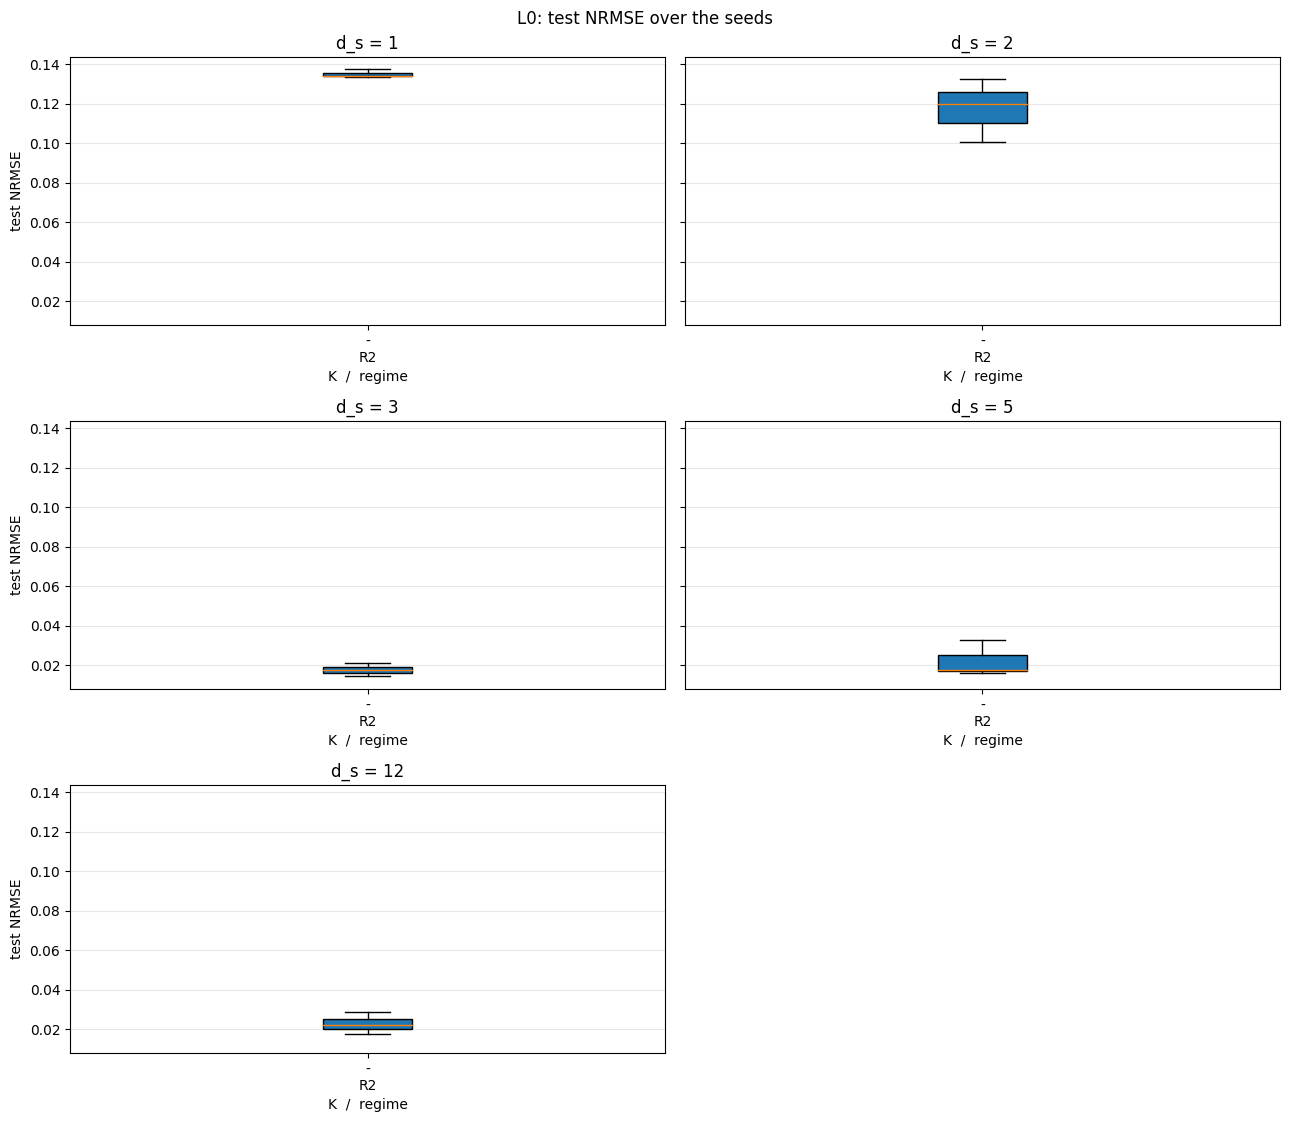

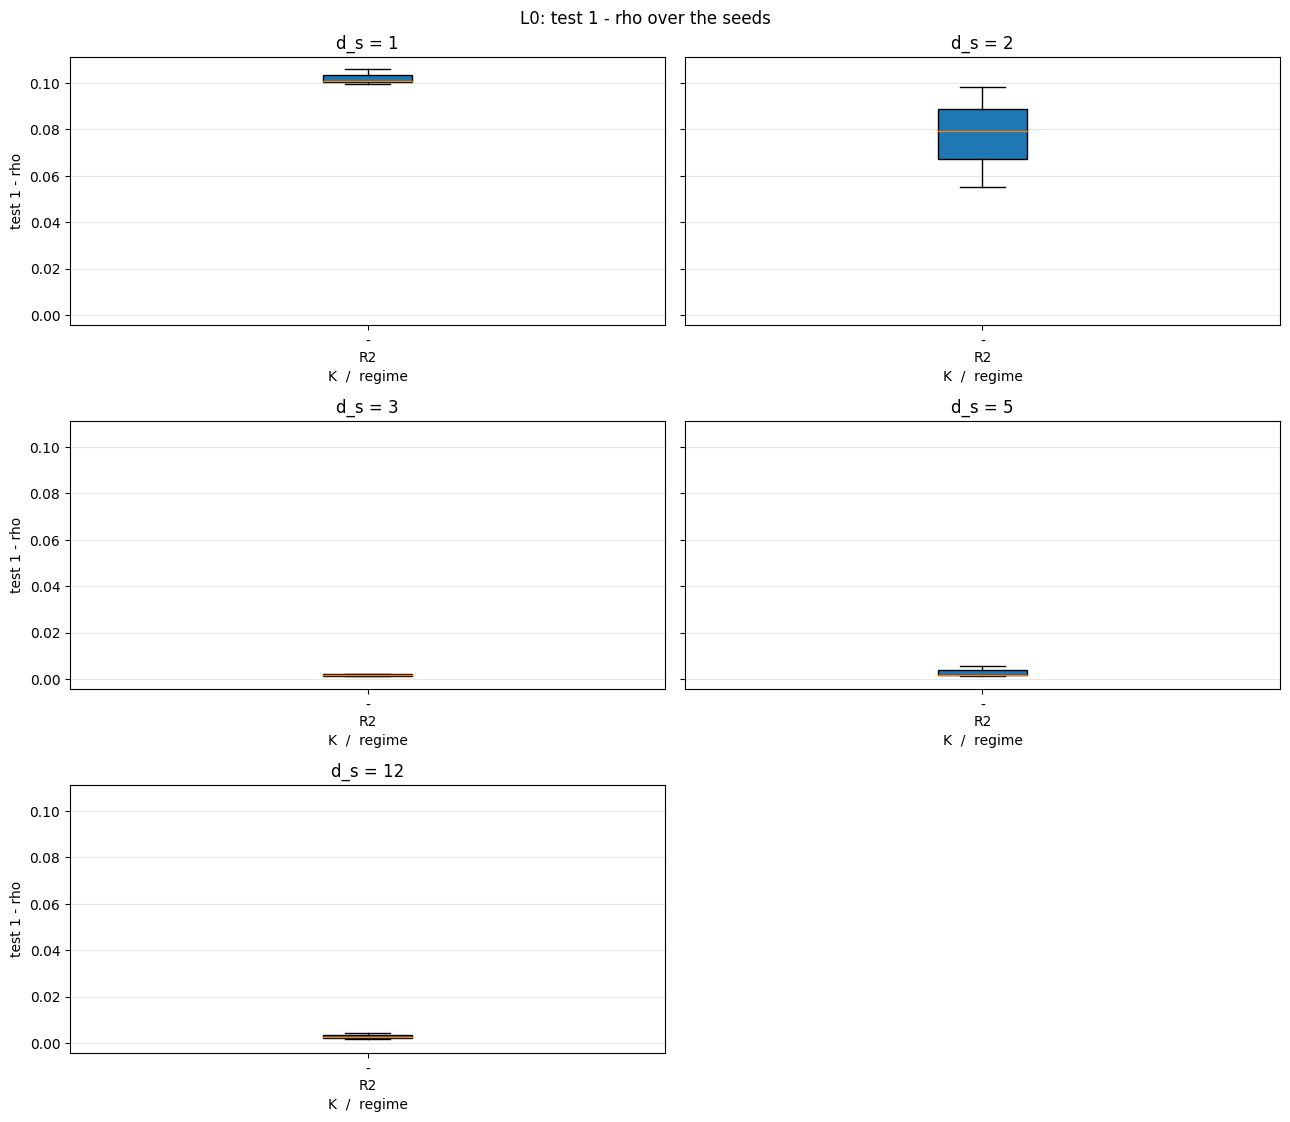

In [13]:
boxplot_variant('L0', 'nrmse_test')
boxplot_variant('L0', 'one_minus_rho_test')

### L0: trend with the dimensionality

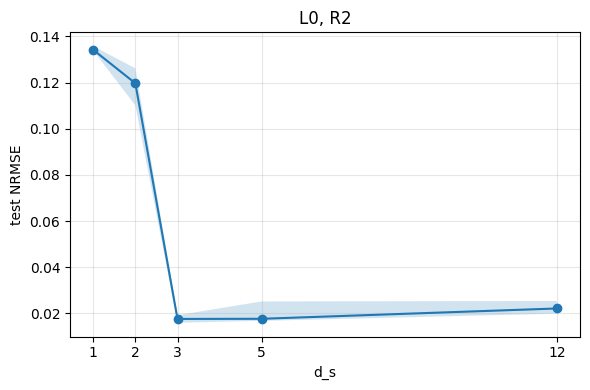

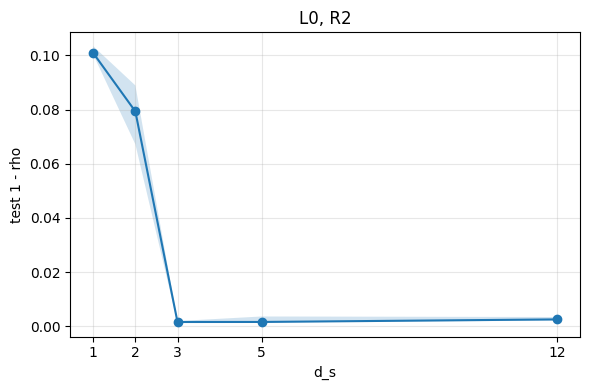

In [14]:
trend_variant('L0', 'nrmse_test')
trend_variant('L0', 'one_minus_rho_test')

## L1: fixed modes, $\bar y+\sum_{k=1}^{d_s}s_k\varphi_k$

The latent states are the coefficients of the first $d_s$ Legendre modes (`build_L1`, $K=d_s$): the reconstructor has **no trainable parameter**. In R2 only $\mathcal{NN}_{\mathrm{dyn}}$ is trained, which forces the latents to be modal. In R1 the fixed formula is just evaluated on the frozen L0 latents (nothing to fit), so R1 measures whether the latents of L0 are modal on their own. On sharp fronts a handful of modes cannot represent the field: expect this variant to fail visibly (protocol H2).

In [17]:
sweep('L1', K_of = lambda d_s: [d_s])

L1: 30 runs to do, 0 already done
[1/30] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L1_R1_ds1_K1_s0          train    0.0 s   test NRMSE 3.202e-01
[2/30] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L1_R2_ds1_K1_s0          train   13.2 s   test NRMSE 2.809e-01
[3/30] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


... (37 outputs left out)

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L1_R1_ds5_K5_s2          train    0.0 s   test NRMSE 3.726e-01
[28/30] L1_R2_ds5_K5_s2          train   20.8 s   test NRMSE 1.664e-01
[29/30] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L1_R1_ds12_K12_s2        train    0.0 s   test NRMSE 3.646e-01
[30/30] L1_R2_ds12_K12_s2        train   22.6 s   test NRMSE 1.325e-01


### L1: comparison of the configurations

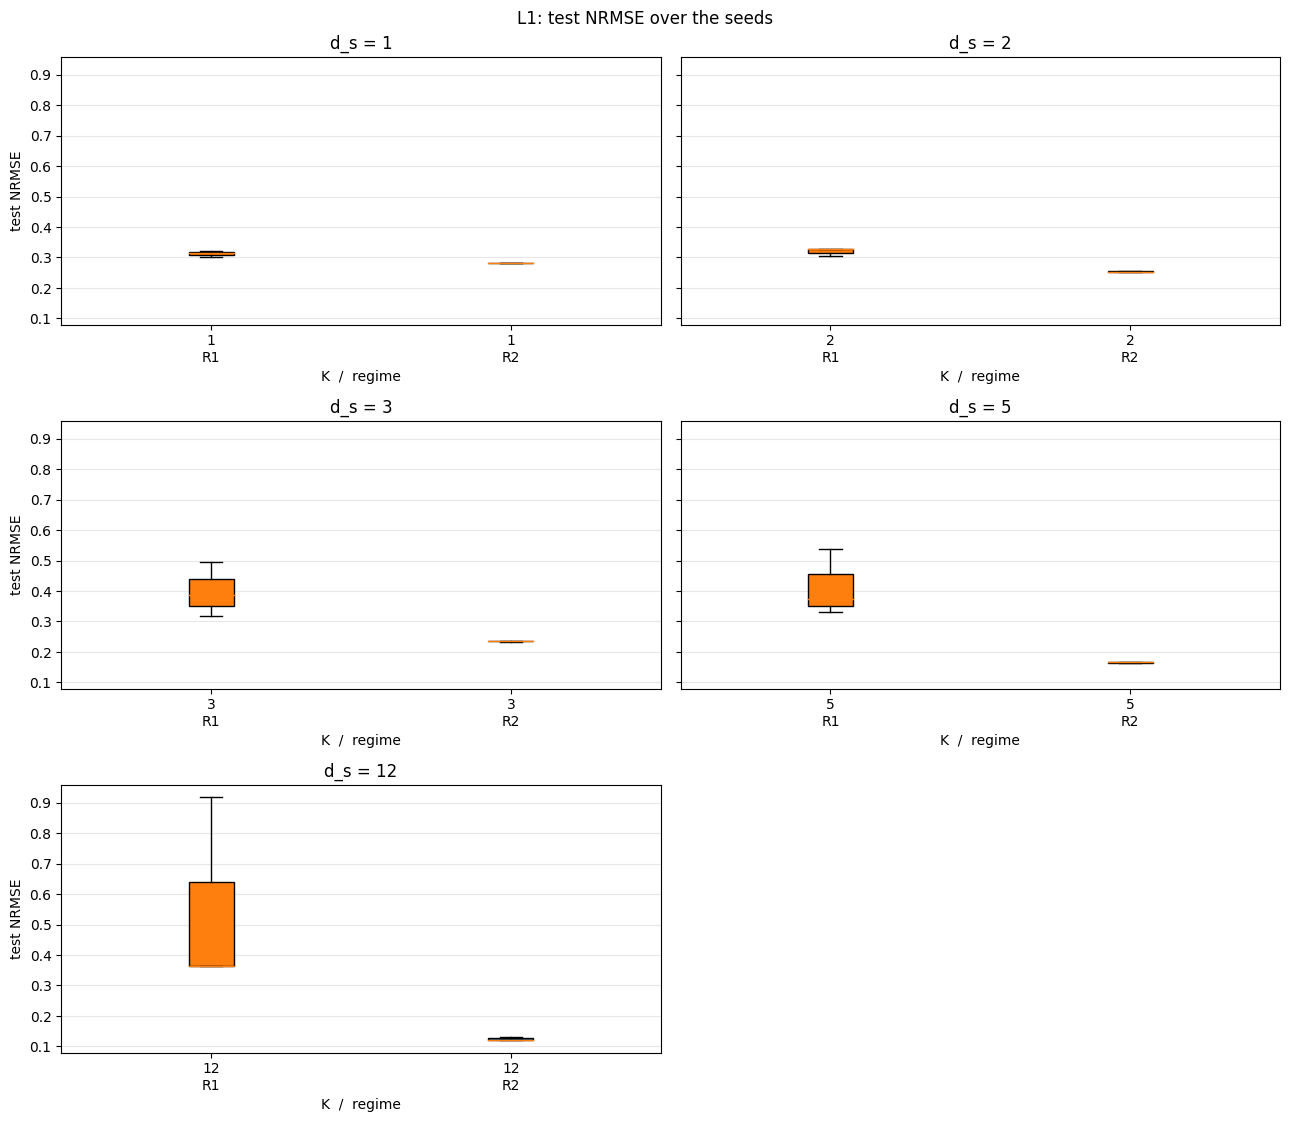

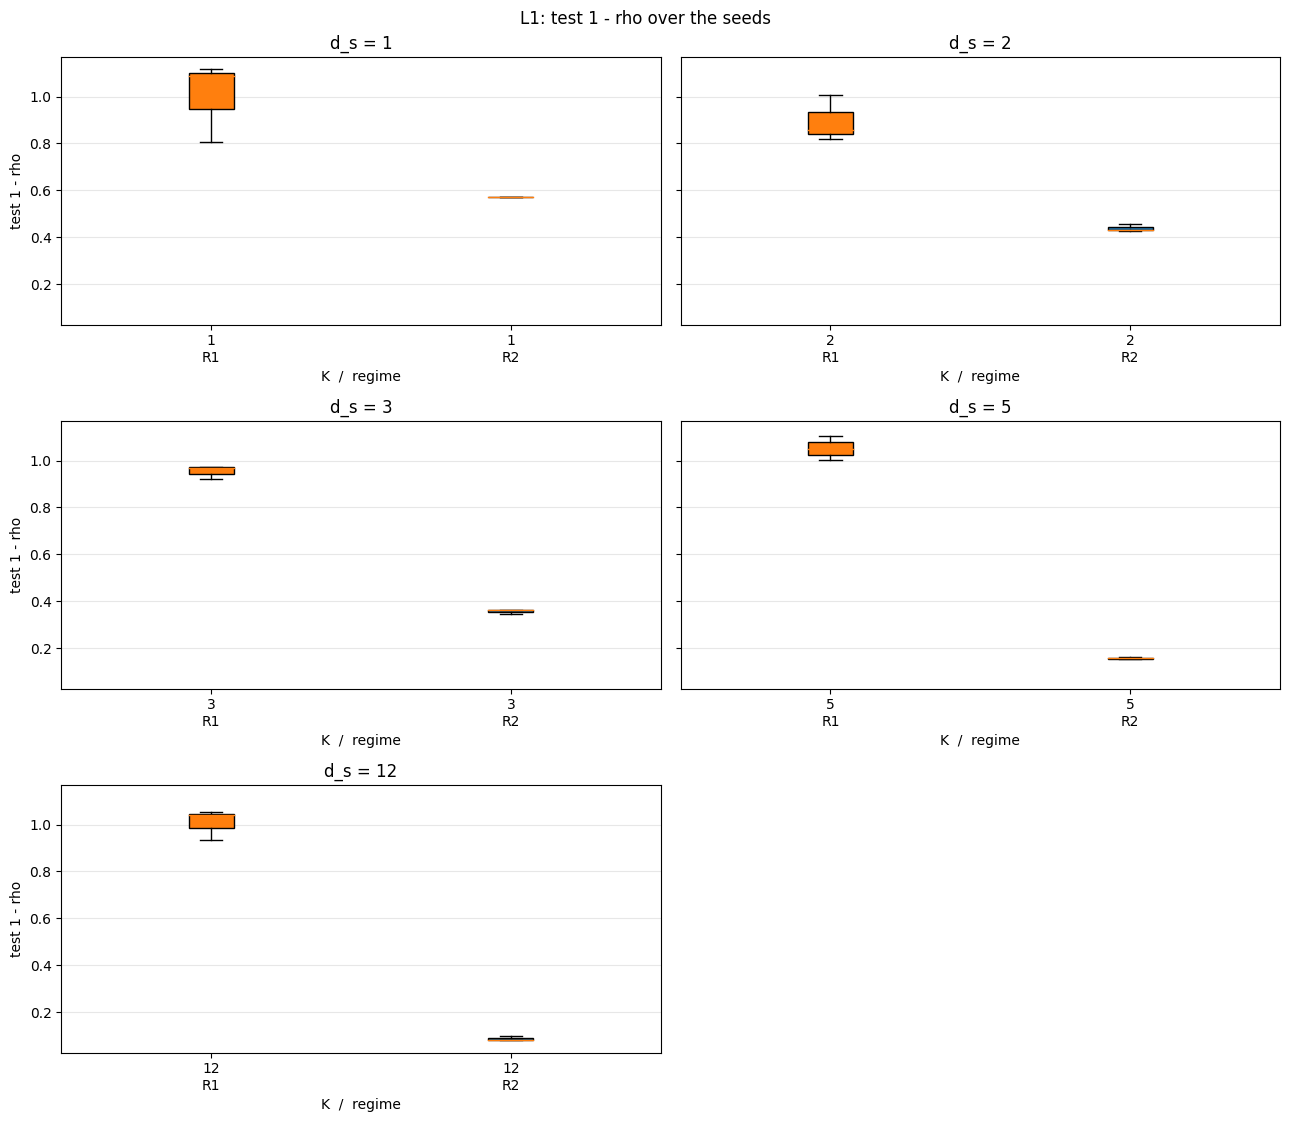

In [15]:
boxplot_variant('L1', 'nrmse_test')
boxplot_variant('L1', 'one_minus_rho_test')

### L1: trend with the dimensionality

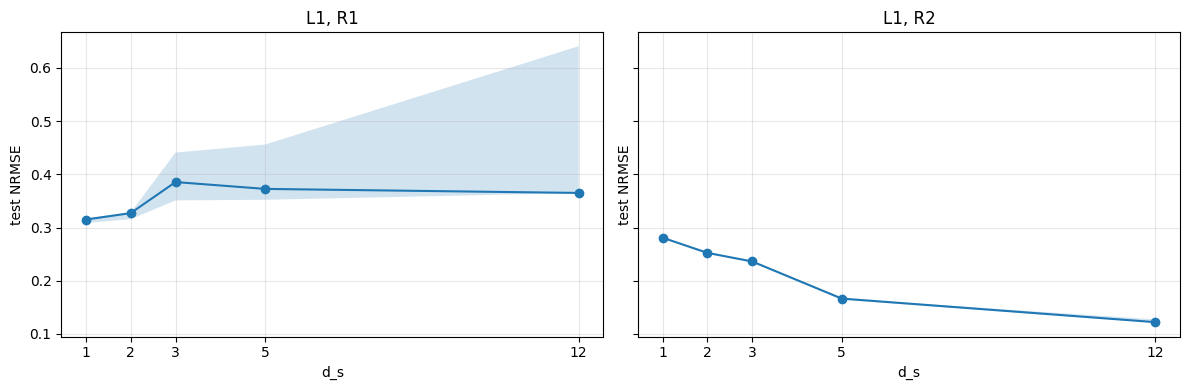

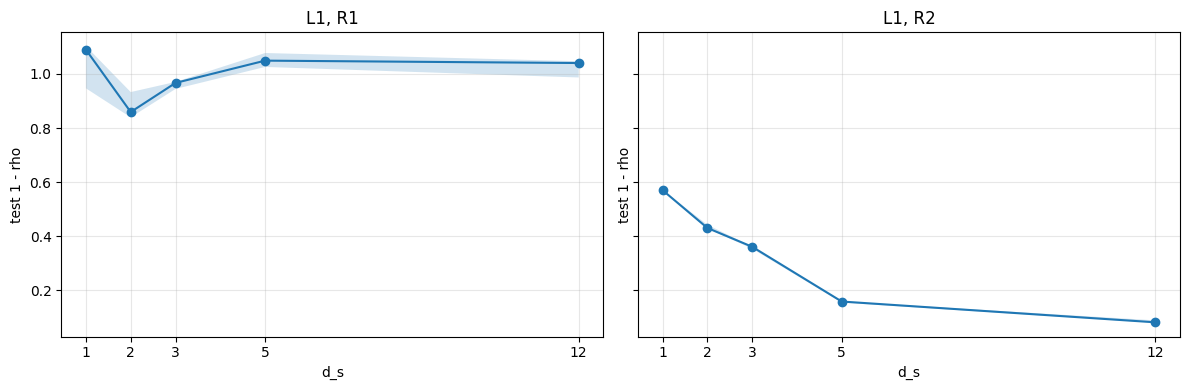

In [16]:
trend_variant('L1', 'nrmse_test')
trend_variant('L1', 'one_minus_rho_test')

## L2: affine map to the modes, $\bar y+\sum_{k=1}^{K}(W\mathbf{s}+\mathbf{b})_k\varphi_k$

The reconstructor (`build_L2`) is linear in the latents with trainable $W\in\mathbb{R}^{K\times d_s}$ and $\mathbf{b}\in\mathbb{R}^K$ ($K(d_s+1)$ parameters), on the fixed Legendre basis. The sweep is over $d_s$ and $K$.

In [20]:
sweep('L2')

L2: 114 runs to do, 0 already done
[1/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L2_R1_ds1_K1_s0          train    2.0 s   test NRMSE 3.018e-01
[2/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L2_R2_ds1_K1_s0          train   11.9 s   test NRMSE 2.726e-01
[3/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


... (131 outputs left out)

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L2_R1_ds5_K17_s2         train    8.1 s   test NRMSE 2.166e-01
[104/114] L2_R2_ds5_K17_s2         train   24.4 s   test NRMSE 1.198e-01
[105/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L2_R1_ds5_K33_s2         train    9.3 s   test NRMSE 2.160e-01
[106/114] L2_R2_ds5_K33_s2         train   25.7 s   test NRMSE 1.269e-01
[107/114] L2_R1_ds12_K5_s2         train    6.5 s   test NRMSE 1.981e-01
[108/114] L2_R2_ds12_K5_s2         train   22.7 s   test NRMSE 1.586e-01
[109/114] L2_R1_ds12_K12_s2        train   11.2 s   test NRMSE 1.797e-01
[110/114] L2_R2_ds12_K12_s2        train   23.0 s   test NRMSE 1.016e-01
[111/114] L2_R1_ds12_K17_s2        train   13.0 s   test NRMSE 1.780e-01
[112/114] L2_R2_ds12_K17_s2        train   24.4 s   test NRMSE 1.019e-01
[113/114] L2_R1_ds12_K33_s2        train   15.9 s   test NRMSE 1.760e-01
[114/114] L2_R2_ds12_K33_s2        train   28.6 s   test NRMSE 1.011e-01


### L2: comparison of the configurations

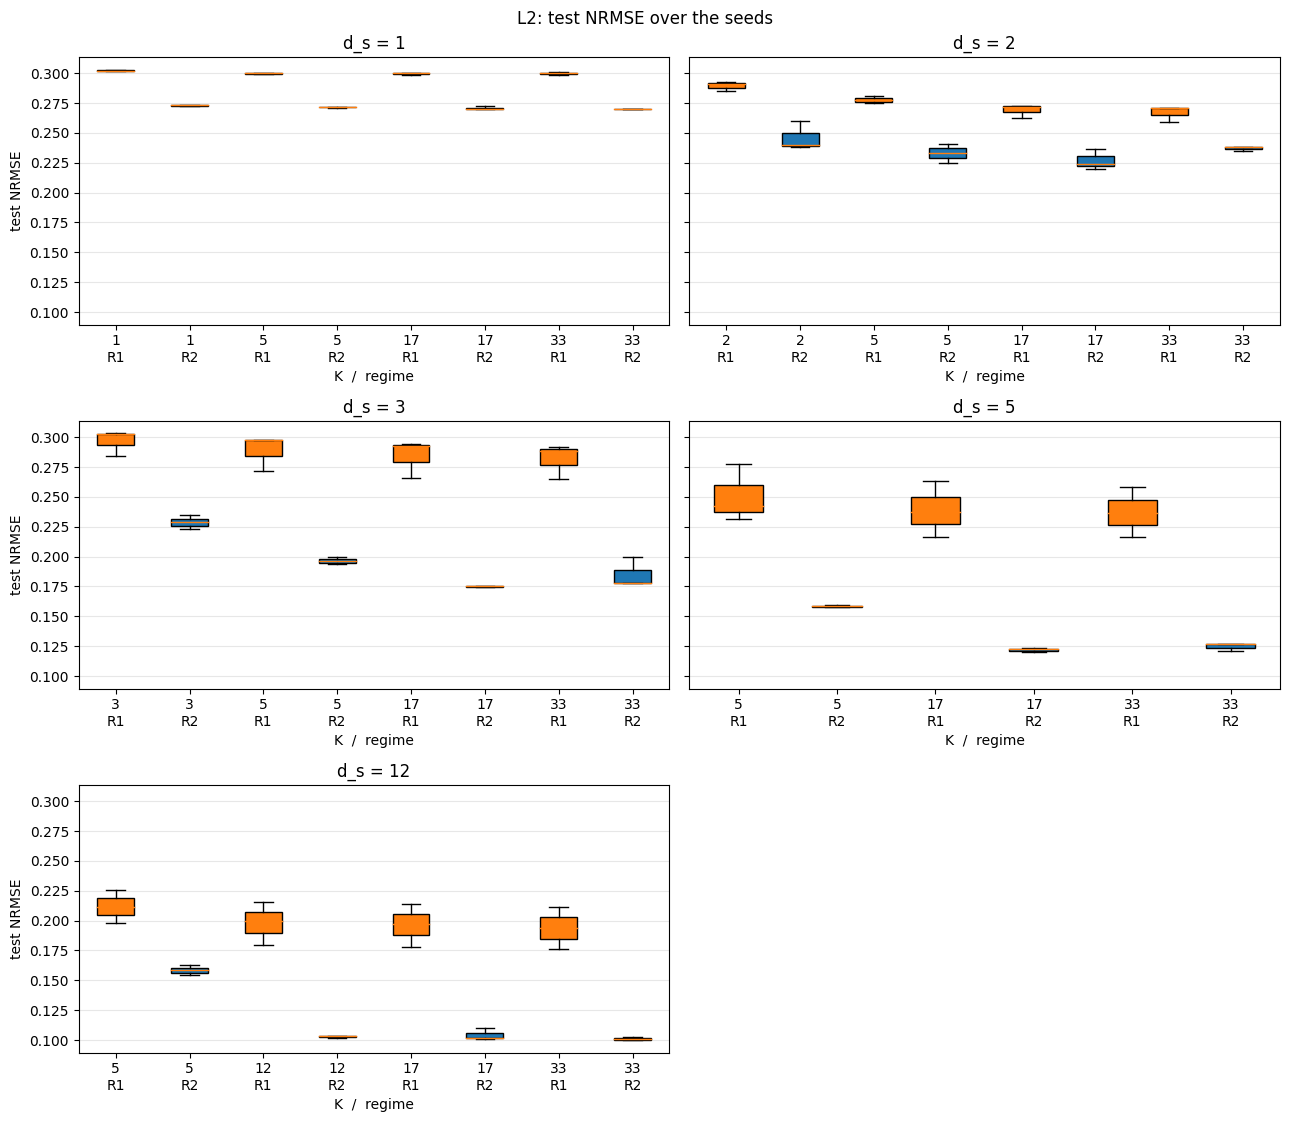

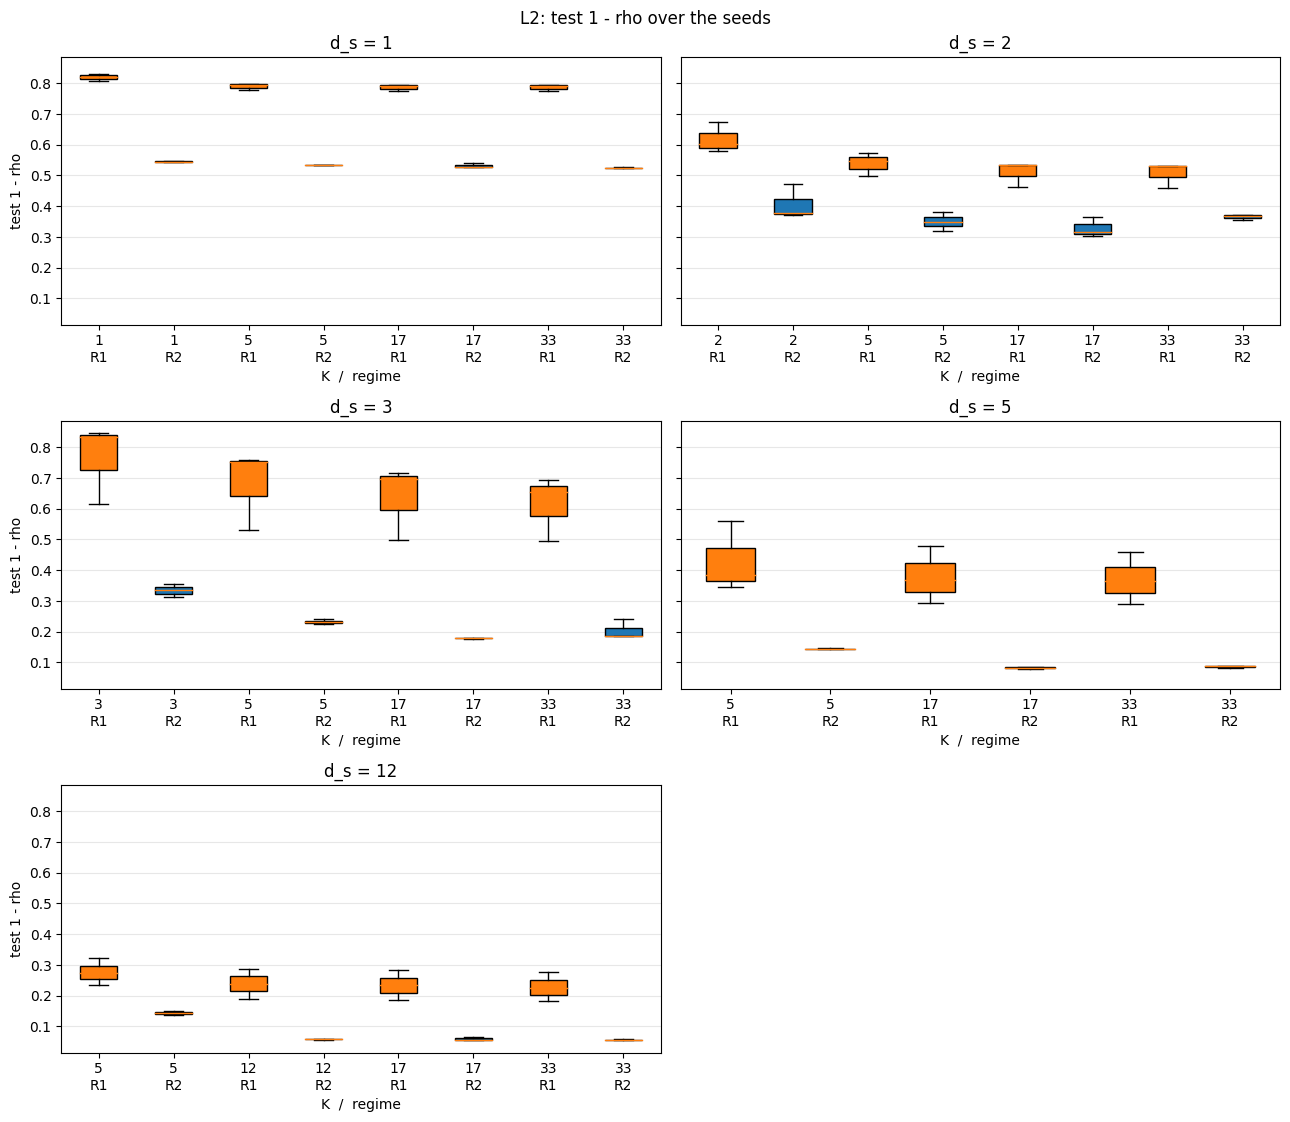

In [17]:
boxplot_variant('L2', 'nrmse_test')
boxplot_variant('L2', 'one_minus_rho_test')

### L2: trend with the dimensionality

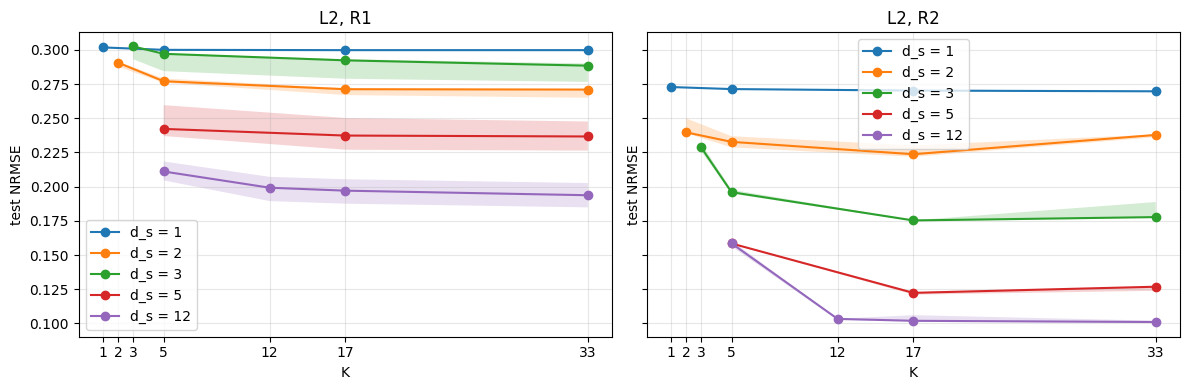

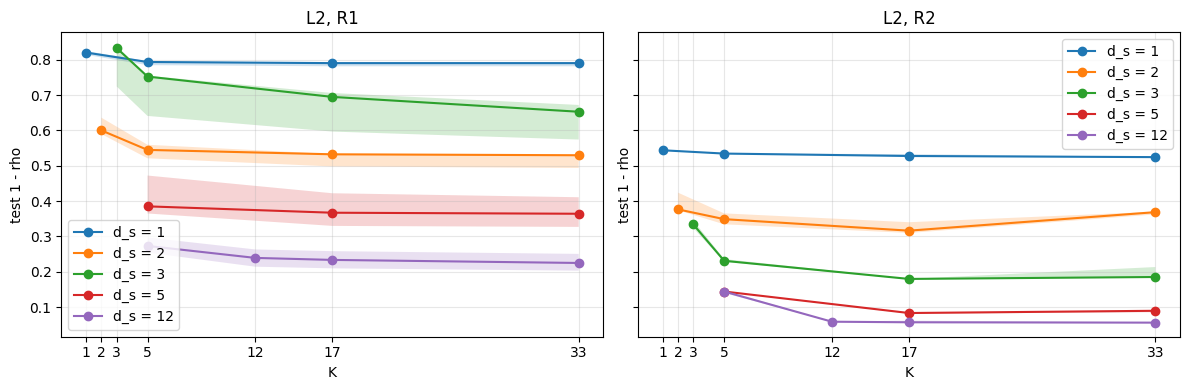

In [18]:
trend_variant('L2', 'nrmse_test')
trend_variant('L2', 'one_minus_rho_test')

## L3: nonlinear map to the modes, $\bar y+\sum_{k=1}^{K}g_\theta(\mathbf{s})_k\varphi_k$

$g_\theta:\mathbb{R}^{d_s}\to\mathbb{R}^K$ (`build_L3`) is a tanh MLP with two hidden layers whose width is the largest one with at most as many parameters as the L0 reconstructor (minimum 1), on the fixed Legendre basis.

**Caution when reading the trend with $K$:** the budget fixes the width, so it shrinks as $K$ grows (see `width` and `rec_params` in `runs.csv`). The large-$K$ points therefore mostly measure a bottleneck of the MLP, not of the basis; a best-size sweep (protocol Sec. 4) is the natural follow-up.

In [23]:
sweep('L3')

L3: 114 runs to do, 0 already done
[1/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L3_R1_ds1_K1_s0          train   27.5 s   test NRMSE 2.708e-01
[2/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/260318097.py:57: RuntimeWarning: Mean of empty slice
  row.update(act_mae_test = float(np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])))))
/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L3_R2_ds1_K1_s0          train   37.3 s   test NRMSE 2.778e-01
[3/114] L3_R1_ds1_K5_s0          train   27.7 s   test NRMSE 2.033e-01
[4/114] L3_R2_ds1_K5_s0          train   37.8 s   test NRMSE 2.115e-01
[5/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


... (45 outputs left out)

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L3_R2_ds1_K33_s2         train   41.0 s   test NRMSE 2.777e-01
[85/114] L3_R1_ds2_K2_s2          train   27.4 s   test NRMSE 2.373e-01
[86/114] L3_R2_ds2_K2_s2          train   39.8 s   test NRMSE 2.265e-01
[87/114] L3_R1_ds2_K5_s2          train   26.6 s   test NRMSE 1.901e-01
[88/114] L3_R2_ds2_K5_s2          train   38.3 s   test NRMSE 1.942e-01
[89/114] L3_R1_ds2_K17_s2         train   27.9 s   test NRMSE 1.694e-01
[90/114] L3_R2_ds2_K17_s2         train   37.8 s   test NRMSE 1.647e-01
[91/114] L3_R1_ds2_K33_s2         train   30.0 s   test NRMSE 1.791e-01
[92/114] L3_R2_ds2_K33_s2         train   40.2 s   test NRMSE 1.731e-01
[93/114] 

/var/folders/46/lfv4tflx1ngf6vjmk2_qtxx80000gn/T/ipykernel_4378/1834508799.py:45: RuntimeWarning: Mean of empty slice
  act_mae = np.nanmean(np.abs(activation_time(app[..., 0]) - activation_time(ref[..., 0])), axis = 1)


L3_R1_ds3_K3_s2          train   27.0 s   test NRMSE 2.151e-01
[94/114] L3_R2_ds3_K3_s2          train   39.1 s   test NRMSE 2.263e-01
[95/114] L3_R1_ds3_K5_s2          train   27.5 s   test NRMSE 1.503e-01
[96/114] L3_R2_ds3_K5_s2          train   39.2 s   test NRMSE 1.748e-01
[97/114] L3_R1_ds3_K17_s2         train   28.6 s   test NRMSE 6.695e-02
[98/114] L3_R2_ds3_K17_s2         train   42.8 s   test NRMSE 1.316e-01
[99/114] L3_R1_ds3_K33_s2         train   29.9 s   test NRMSE 6.828e-02
[100/114] L3_R2_ds3_K33_s2         train   41.8 s   test NRMSE 1.071e-01
[101/114] L3_R1_ds5_K5_s2          train   28.7 s   test NRMSE 1.506e-01
[102/114] L3_R2_ds5_K5_s2          train   41.0 s   test NRMSE 1.506e-01
[103/114] L3_R1_ds5_K17_s2         train   29.1 s   test NRMSE 7.251e-02
[104/114] L3_R2_ds5_K17_s2         train   42.1 s   test NRMSE 7.799e-02
[105/114] L3_R1_ds5_K33_s2         train   31.0 s   test NRMSE 7.085e-02
[106/114] L3_R2_ds5_K33_s2         train   43.7 s   test NRMSE 8.06

### L3: comparison of the configurations

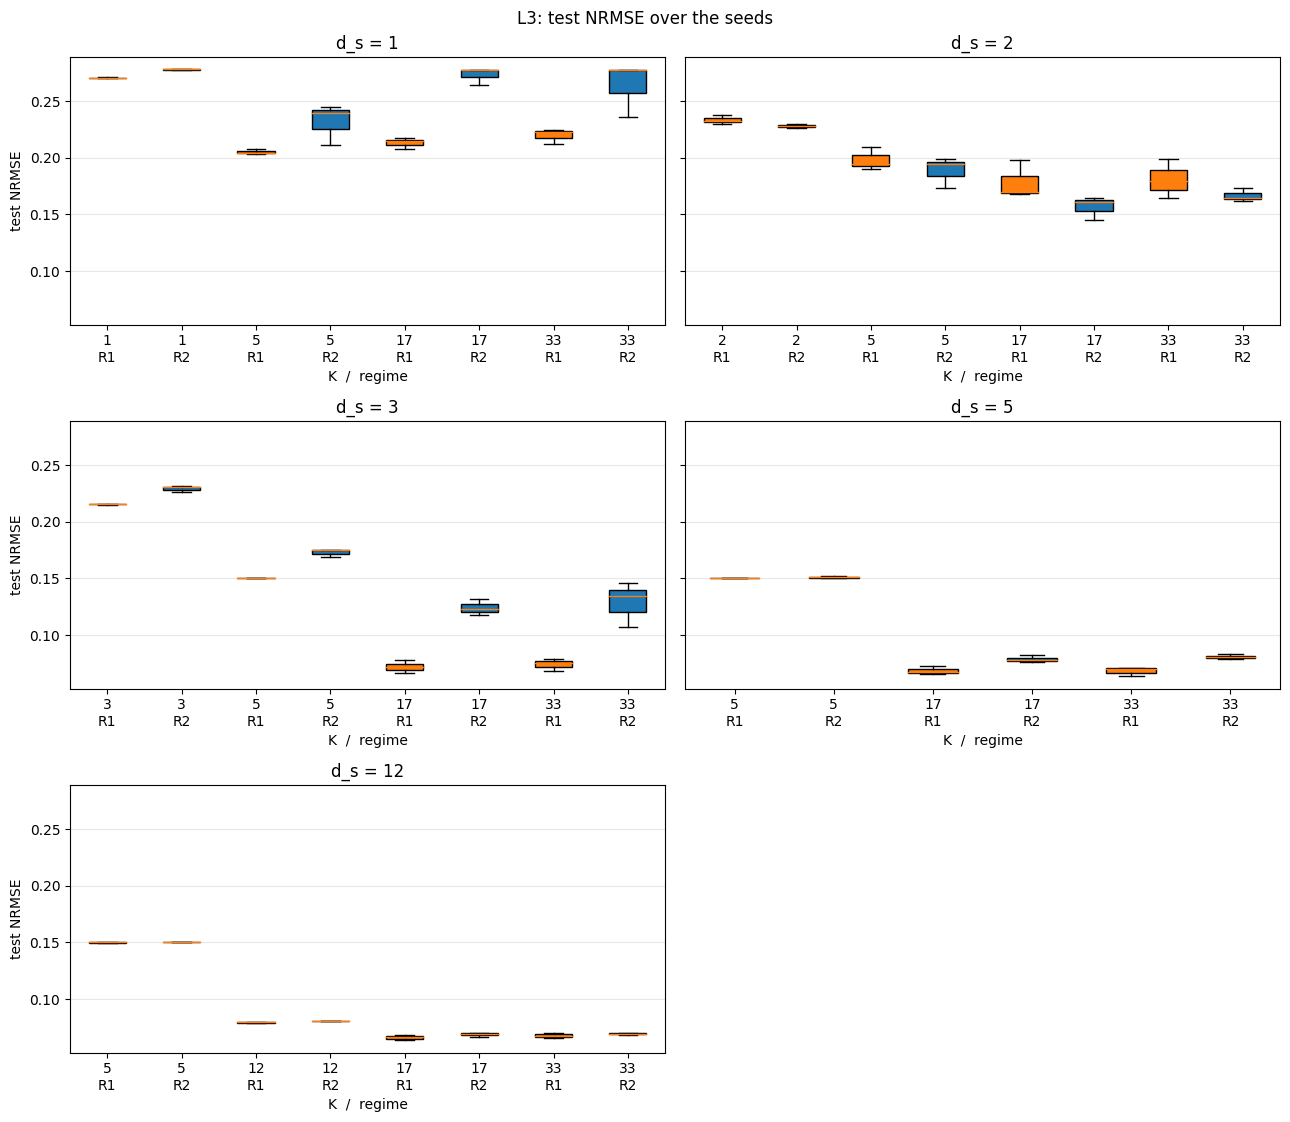

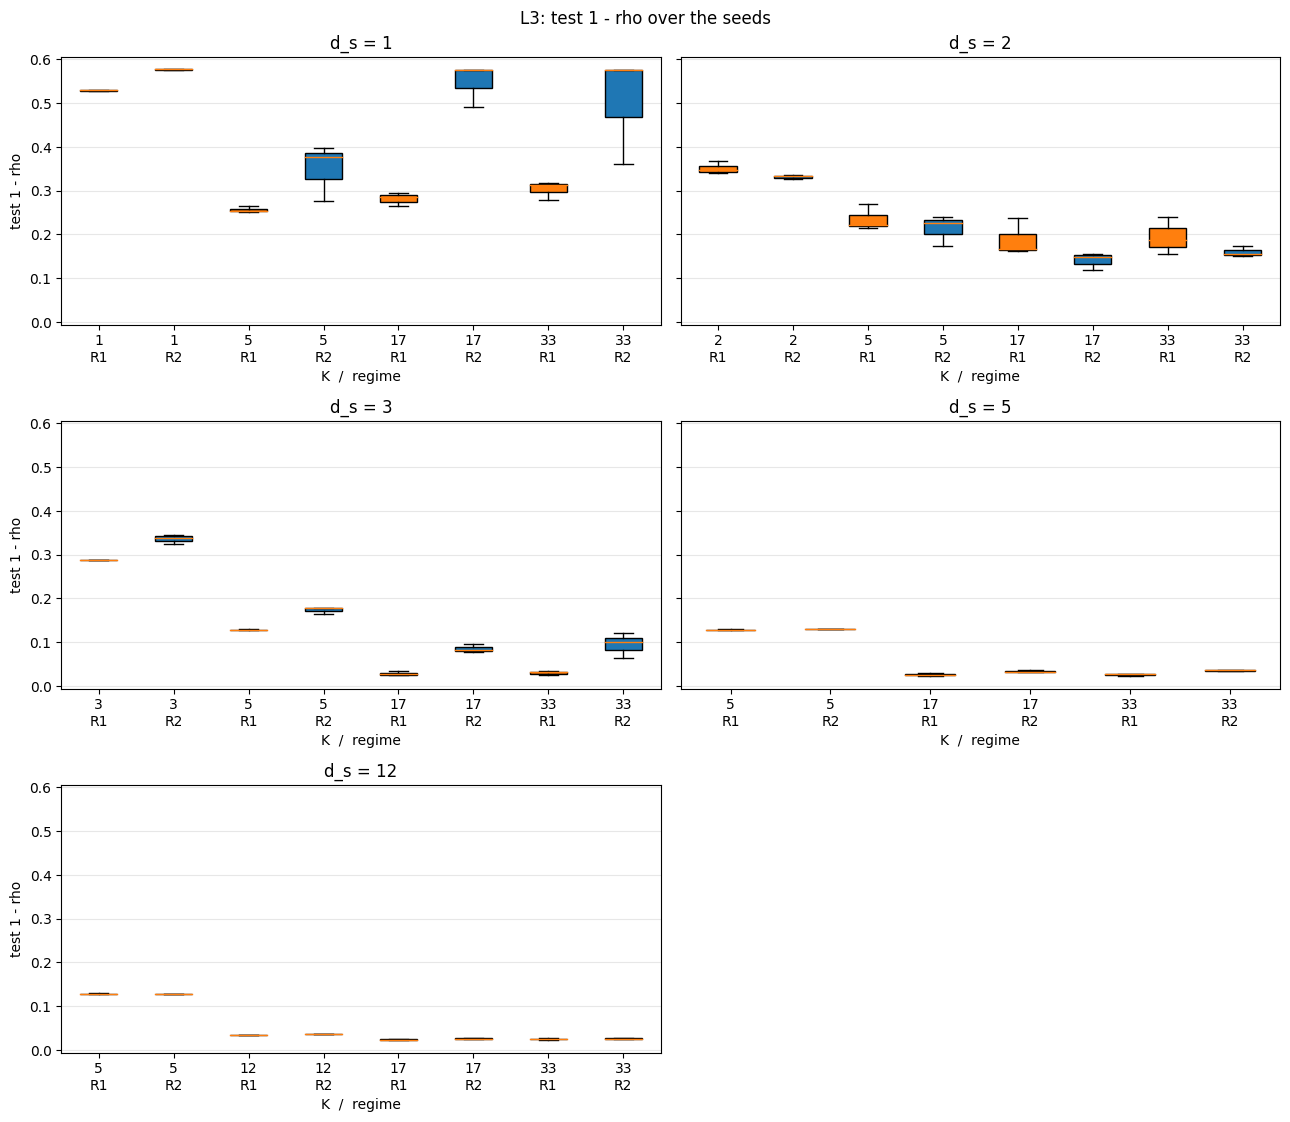

In [19]:
boxplot_variant('L3', 'nrmse_test')
boxplot_variant('L3', 'one_minus_rho_test')

### L3: trend with the dimensionality

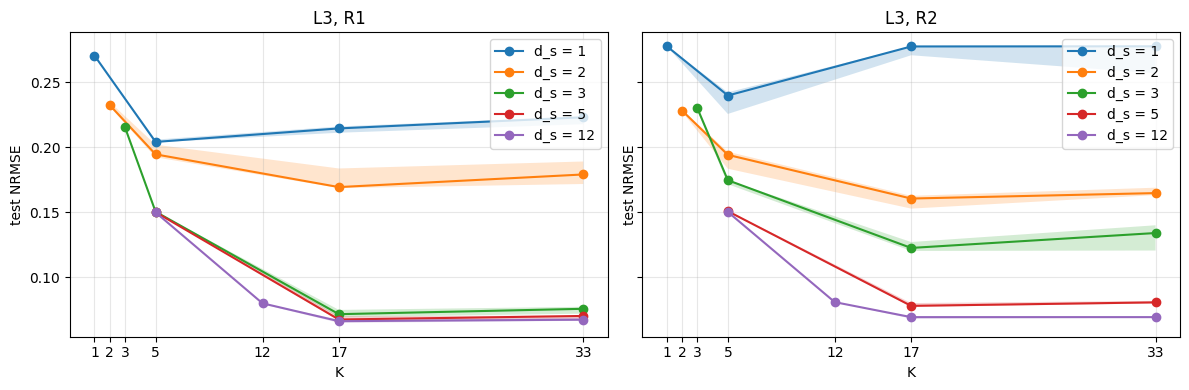

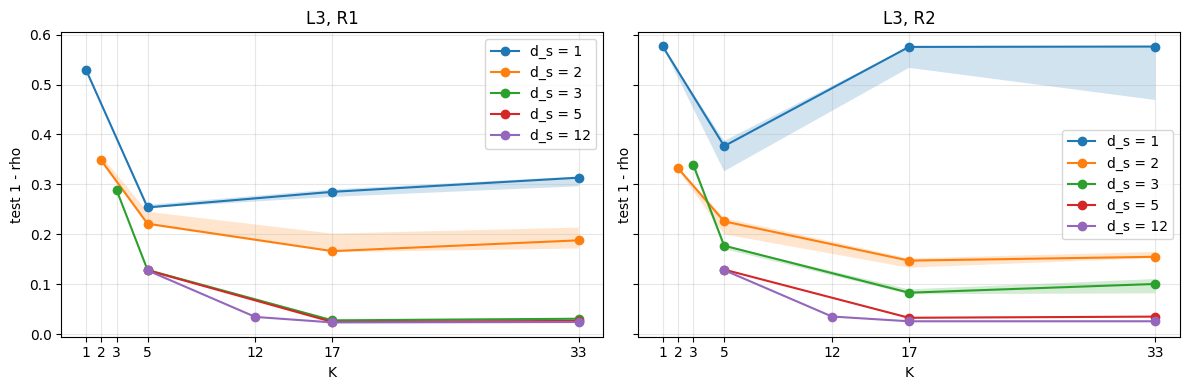

In [20]:
trend_variant('L3', 'nrmse_test')
trend_variant('L3', 'one_minus_rho_test')

## Final comparison: the best configuration of every procedure

A procedure is a variant with a regime (L0 appears once). Its **best configuration** is the $(d_s,K)$ with the lowest median validation NRMSE over the seeds: the test set is never used to choose (pass `select = 'nrmse_test'` to `best_configs` to choose on it instead). The table shows the medians over the seeds, then a boxplot over the seeds compares the procedures.

In [23]:
CONFIG = ['variant', 'regime', 'd_s', 'K']

def best_configs(select = 'nrmse_valid'):
    '''For every (variant, regime): the (d_s, K) with the lowest median `select` over the seeds.'''
    med = load('runs').groupby(CONFIG)[select].median().reset_index()
    return med.loc[med.groupby(['variant', 'regime'])[select].idxmin(), CONFIG]

best = best_configs()
best_runs = load('runs').merge(best, on = CONFIG)                           # all the seeds of the best configurations

columns = ['rec_params', 'nrmse_train', 'nrmse_test', 'one_minus_rho_train', 'one_minus_rho_test',
           'eps_total_test', 'eps_proj_test', 'eff_ratio_test',
           'act_mae_test', 'train_time_s', 'infer_time_s']
table = best_runs.groupby(CONFIG)[columns].median().reset_index()
table['rec_params'] = table['rec_params'].astype(int)
print(table.to_string(index = False, float_format = lambda v: '%1.3e' % v))

variant regime  d_s  K  rec_params  nrmse_train  nrmse_test  one_minus_rho_train  one_minus_rho_test  eps_total_test  eps_proj_test  eff_ratio_test  act_mae_test  train_time_s  infer_time_s
     L0     R2    5  0        1361    1.613e-02   1.764e-02            9.952e-04           1.656e-03       5.062e-02            NaN             NaN     1.000e+00     1.337e+02     3.668e-01
     L1     R1    1  1           0    3.702e-01   3.150e-01            1.096e+00           1.089e+00       9.041e-01      7.432e-01       1.217e+00     3.191e+02     0.000e+00     4.017e-03
     L1     R2   12 12           0    1.336e-01   1.221e-01            7.046e-02           8.231e-02       3.504e-01      2.155e-01       1.626e+00     8.349e+00     2.254e+01     1.852e-03
     L2     R1   12 33         429    2.193e-01   1.937e-01            2.041e-01           2.248e-01       5.561e-01      7.063e-02       7.874e+00     2.656e+01     1.590e+01     6.094e-03
     L2     R2   12 33         429    1.103e-01   

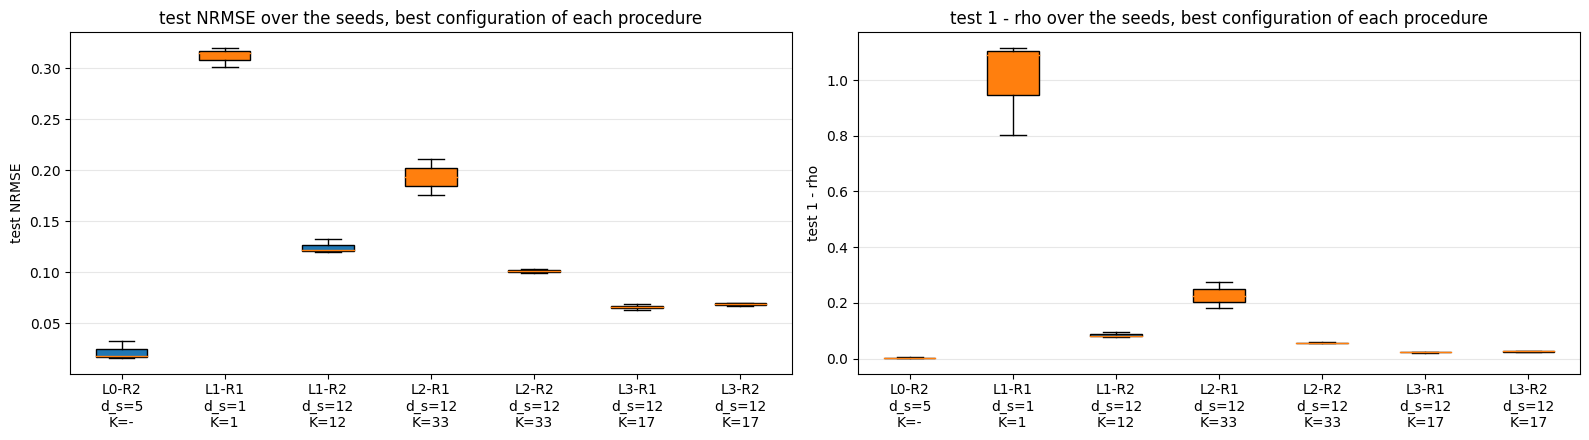

In [24]:
fig, axs = plt.subplots(1, 2, figsize = (16, 4.5))
groups = list(best_runs.groupby(CONFIG))
for ax, metric in zip(axs, ['nrmse_test', 'one_minus_rho_test']):
    bp = ax.boxplot([g[metric].values for _, g in groups], patch_artist = True,
                    labels = [f"{v}-{r}\nd_s={d}\nK={K if K else '-'}" for (v, r, d, K), _ in groups])
    for patch, ((v, r, d, K), _) in zip(bp['boxes'], groups):
        patch.set_facecolor(REGIME_COLOR[r])
    ax.set(ylabel = LABEL[metric], yscale = 'linear', title = f'{LABEL[metric]} over the seeds, best configuration of each procedure')
    ax.grid(True, axis = 'y', alpha = 0.3)
fig.tight_layout()
plt.show()

### Predictions compared to the FOM

For every procedure, the seed with the lowest validation NRMSE of its best configuration, rebuilt from the saved weights (the check verifies that the rebuilt model gives the stored test NRMSE). FOM on the left, reduced model on the right, as in the original script.

L0-R2: d_s = 5, K = -, seed 0, test NRMSE 1.585e-02


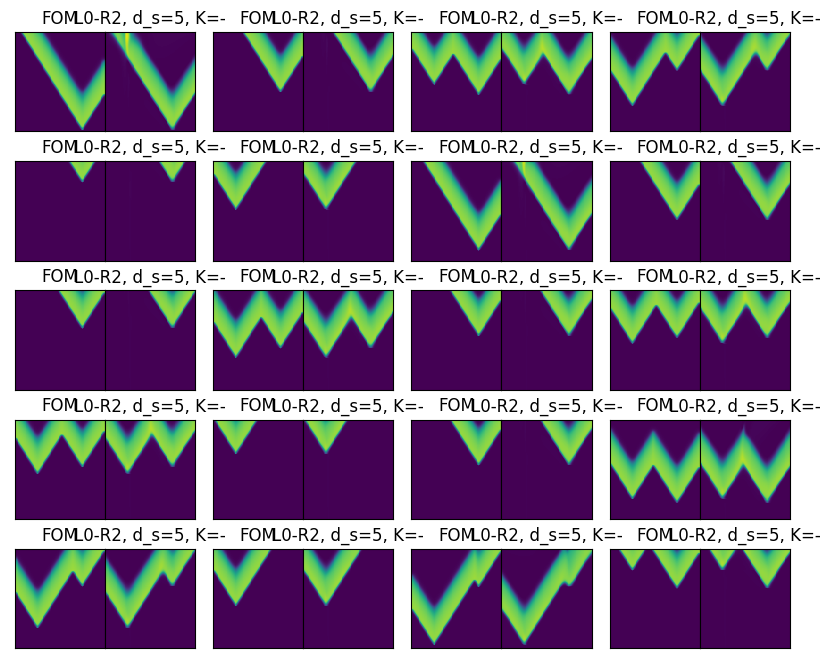

L1-R1: d_s = 1, K = 1, seed 1, test NRMSE 3.018e-01


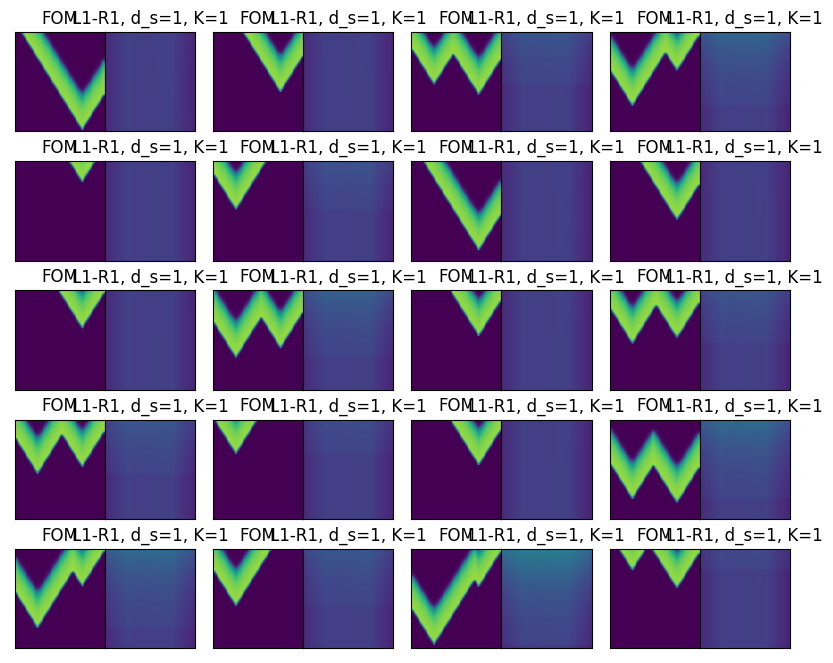

L1-R2: d_s = 12, K = 12, seed 0, test NRMSE 1.221e-01


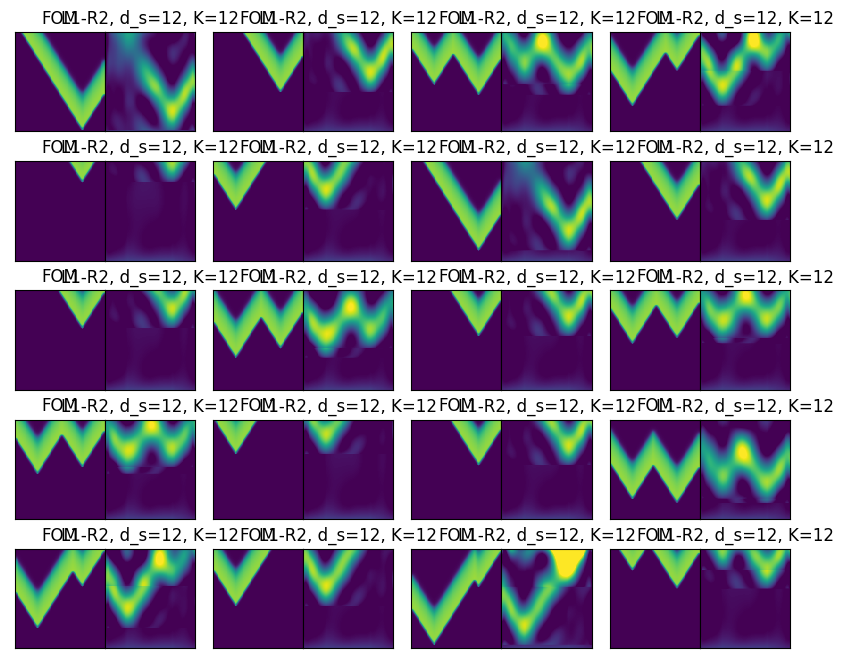

L2-R1: d_s = 12, K = 33, seed 2, test NRMSE 1.760e-01


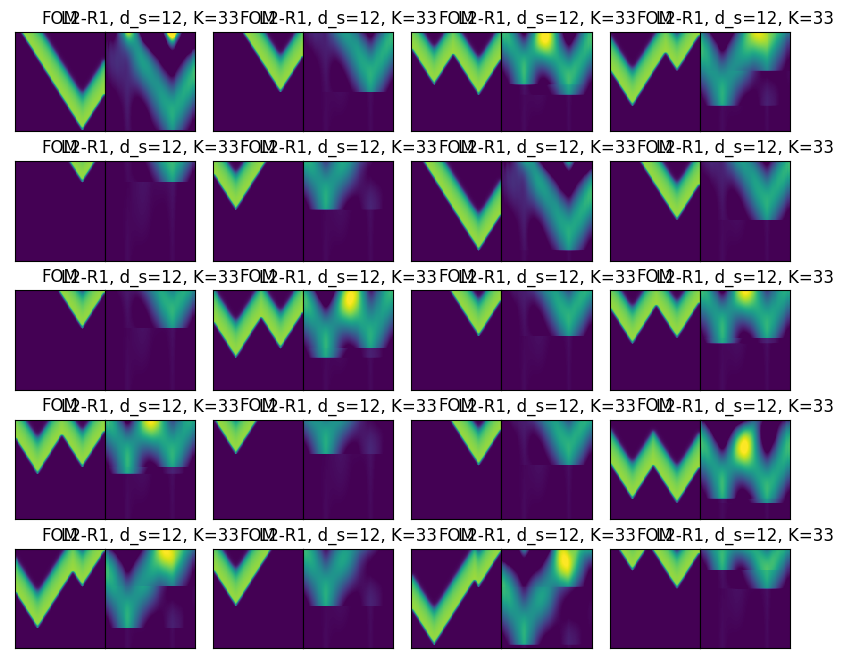

L2-R2: d_s = 12, K = 33, seed 1, test NRMSE 9.979e-02


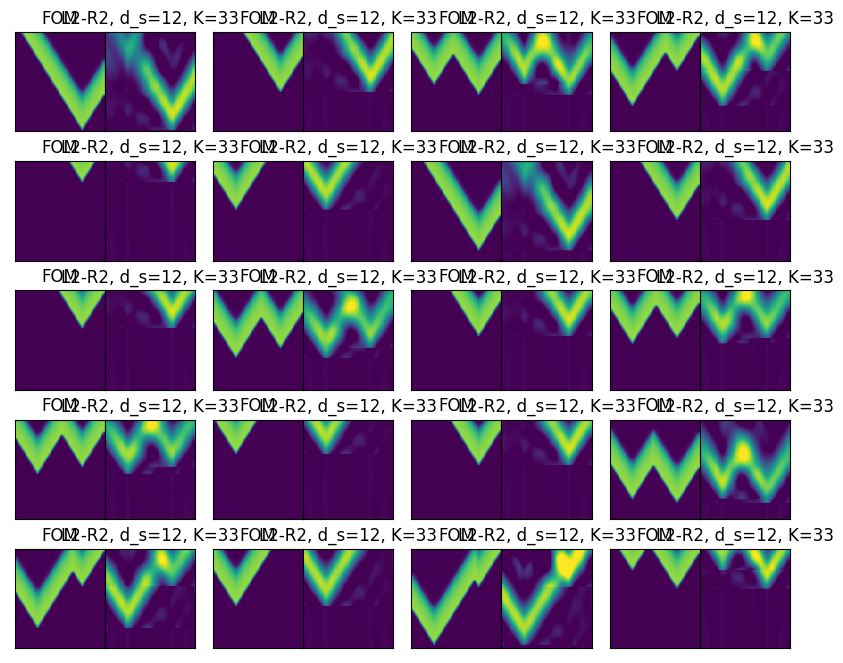

L3-R1: d_s = 12, K = 17, seed 2, test NRMSE 6.357e-02


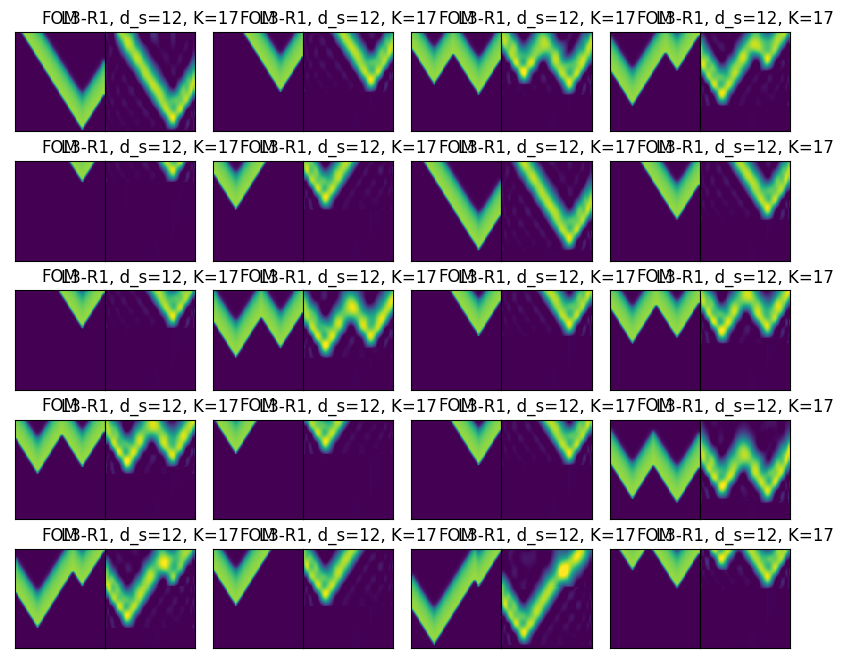

L3-R2: d_s = 12, K = 17, seed 2, test NRMSE 6.695e-02


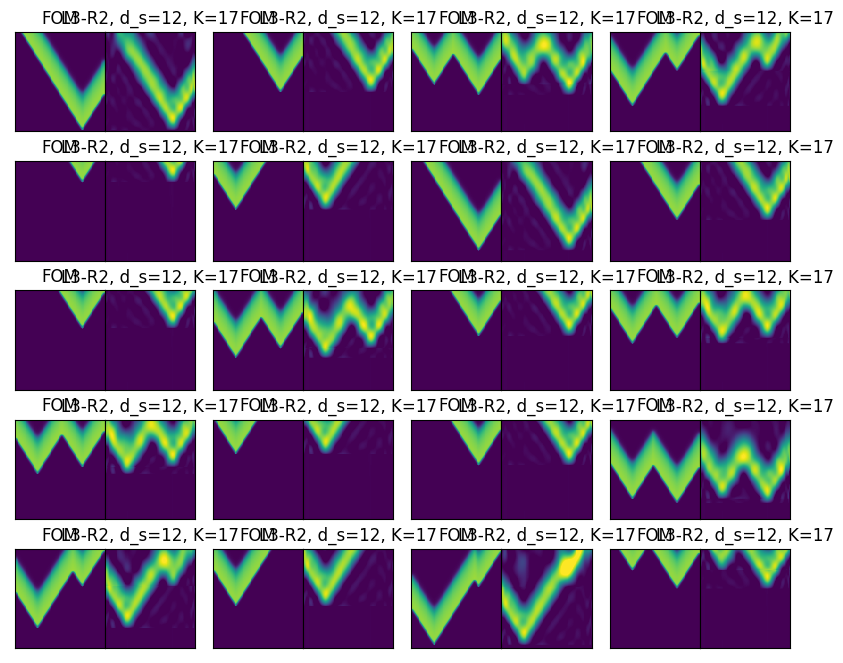

In [25]:
for (variant, regime, d_s, K), g in best_runs.groupby(CONFIG):
    best_run = g.loc[g.nrmse_valid.idxmin()]
    pred = predict_test(variant, regime, d_s, K, int(best_run.seed))
    print(f'{variant}-{regime}: d_s = {d_s}, K = {K if K else "-"}, seed {int(best_run.seed)}, test NRMSE {best_run.nrmse_test:.3e}')
    assert np.isclose(nrmse_rho(pred, REF['test'])[0], best_run.nrmse_test, rtol = 1e-6), 'rebuilt model does not match the stored result'
    utils.plot_output_1D(dataset_tests, REF['test'], pred, 5, 4, title_ROM = f'{variant}-{regime}, d_s={d_s}, K={K if K else "-"}')
    plt.show()